In [ ]:
# imbalanced-learn: librería que contiene SMOTE-NC y el Pipeline que aplica el sobremuestreo
# solo al entrenamiento de cada pliegue (sección C.1).
!pip install -q --root-user-action=ignore imbalanced-learn

In [ ]:
import json, unicodedata, warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import requests
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import wilcoxon, t as dist_t

from sklearn.model_selection import (train_test_split, StratifiedKFold, RepeatedStratifiedKFold,
                                     GridSearchCV, cross_validate)
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import FunctionTransformer, StandardScaler, OneHotEncoder
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression, LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.feature_selection import mutual_info_classif
from sklearn.inspection import permutation_importance
from sklearn.metrics import (f1_score, recall_score, precision_score, accuracy_score,
                             confusion_matrix, ConfusionMatrixDisplay, make_scorer,
                             matthews_corrcoef, average_precision_score)
from imblearn.pipeline import Pipeline
from imblearn.over_sampling import SMOTE, SMOTENC

SEED = 42
ORDEN = ["Bajo", "Medio", "Alto"]
MODELOS = ["KNN", "Arbol", "Regresion"]
pd.set_option("display.max_columns", 40)
pd.set_option("display.float_format", lambda v: f"{v:.4f}")
sns.set_theme(style="whitegrid")

ARCHIVO_INDECI = "BD-EMER-Y-DAÑOS-INTEGRADA-2003-2020-validada.xlsx"
# Versiones fijas (commit concreto) para que el resultado sea reproducible aunque los repositorios cambien
URL_GEOJSON = "https://raw.githubusercontent.com/juaneladio/peru-geojson/3213eeb1bbe537f88dead45a2aadaa276fa9451d/peru_distrital_simple.geojson"
URL_ALTITUD = "https://raw.githubusercontent.com/jmcastagnetto/ubigeo-peru-aumentado/a783fa66effb16fa8f3321b49a3d5e71cab15a5c/ubigeo_distrito.csv"

# Parte A. Construcción del dataset

## A.1 Lectura de la base del INDECI
Una fila = una emergencia (2003-2020). La fila de encabezados se detecta automáticamente y los nombres de columna se normalizan (sin tildes, puntos ni espacios extra), para que la lectura funcione con cualquier versión del Excel.

In [ ]:
def clave(s):
    s = unicodedata.normalize("NFKD", str(s)).encode("ascii", "ignore").decode()
    return " ".join(s.upper().replace(".", " ").split())

crudo = pd.read_excel(ARCHIVO_INDECI, sheet_name="BD 2003-2020", header=None, nrows=15)
fila_enc = next(i for i in crudo.index if any("DISTRITO" in clave(v) for v in crudo.loc[i].values))
emerg = pd.read_excel(ARCHIVO_INDECI, sheet_name="BD 2003-2020", header=fila_enc)

buscar = {"COD DISTRITO": "COD. DISTRITO", "ANO": "AÑO", "EMERGENCIA": "EMERGENCIA",
          "REGION NATURAL": "REGIÓN NATURAL", "FALLECIDOS": "FALLECIDOS",
          "DAMNIFICADOS": "DAMNIFICADOS", "VIVIENDAS DESTRUIDAS": "VIVIENDAS DESTRUIDAS",
          "VIVIENDAS AFECTADAS": "VIVIENDAS AFECTADAS", "HAS CULTIVO DESTRUIDO": "HAS CULTIVO DESTRUIDO"}
emerg = emerg.rename(columns={c: buscar[clave(c)] for c in emerg.columns if clave(c) in buscar})
faltan_cols = [v for v in buscar.values() if v not in emerg.columns]
assert not faltan_cols, f"No se encontraron: {faltan_cols}"

emerg = emerg.dropna(subset=["COD. DISTRITO"])
emerg["ubigeo"] = (pd.to_numeric(emerg["COD. DISTRITO"], errors="coerce")
                     .astype("Int64").astype(str).str.zfill(6))
COL_FECHA = [c for c in emerg.columns if "FECHA" in clave(c)][0]
print("Encabezados en la fila:", fila_enc, "| Emergencias:", len(emerg))

Encabezados en la fila: 0 | Emergencias: 96526


## A.2 Filtro de huaicos y duplicados
Se conservan las emergencias de tipo huaico. Un registro con el mismo distrito, fecha **y** daños es el mismo reporte cargado dos veces, por lo que se elimina. Si el distrito y la fecha coinciden pero los daños difieren, se conservan y se suman (supuesto: son eventos o reportes distintos). Como podrían ser actualizaciones del mismo evento, en A.4 se verifica que sumar o tomar el máximo no cambie la etiqueta.

In [ ]:
h = emerg[emerg["EMERGENCIA"].astype(str).str.upper().str.contains("HUAICO|HUAYCO", na=False)].copy()
DANOS = ["FALLECIDOS", "DAMNIFICADOS", "VIVIENDAS DESTRUIDAS", "VIVIENDAS AFECTADAS", "HAS CULTIVO DESTRUIDO"]
h[DANOS] = h[DANOS].apply(pd.to_numeric, errors="coerce").fillna(0)
print("Registros de huaico:", len(h))

CLAVE_DUP = ["ubigeo", COL_FECHA]
rep = h[h.duplicated(CLAVE_DUP, keep=False)]
print("Registros que comparten distrito y fecha:", len(rep))
print("  - copias exactas (mismos daños):", h.duplicated(CLAVE_DUP + DANOS).sum())
print("  - grupos con daños distintos (se conservan):",
      (rep.groupby(CLAVE_DUP)[DANOS].nunique().max(axis=1) > 1).sum())

h = h.drop_duplicates(CLAVE_DUP + DANOS, keep="first")
h_max = h.groupby(CLAVE_DUP, as_index=False).agg({**{d: "max" for d in DANOS}, "AÑO": "first"})   # alternativa para A.4
print("Registros tras eliminar copias exactas:", len(h))

Registros de huaico: 2276
Registros que comparten distrito y fecha: 231
  - copias exactas (mismos daños): 91
  - grupos con daños distintos (se conservan): 46
Registros tras eliminar copias exactas: 2185


## A.3 Agregación por distrito y separación temporal
- **Entradas (X):** historial 2003-2014.
- **Etiqueta (y):** daños 2015-2020.

Al separar los periodos, el modelo no ve información del periodo que debe predecir (se evita la fuga de datos). `huaicos` cuenta fechas distintas, no filas.

La lista de distritos es la del límite distrital del INEI (GeoJSON). Los registros de distritos que no están en esa lista (creados después) no se pueden asignar y se pierden; además, en un distrito creado durante el periodo, su historial puede estar registrado bajo el distrito del que se separó.

In [ ]:
def agregar(sub, suf):
    g = sub.groupby("ubigeo").agg(
        huaicos=(COL_FECHA, "nunique"),
        fallecidos=("FALLECIDOS", "sum"),
        damnificados=("DAMNIFICADOS", "sum"),
        viv_destruidas=("VIVIENDAS DESTRUIDAS", "sum"),
        viv_afectadas=("VIVIENDAS AFECTADAS", "sum"),
        has_destruidas=("HAS CULTIVO DESTRUIDO", "sum"))
    return g.add_suffix(suf)

hist = agregar(h[h["AÑO"] <= 2014], "_2003_2014")
futuro = agregar(h[h["AÑO"] >= 2015], "_2015_2020")[
    ["huaicos_2015_2020", "damnificados_2015_2020", "fallecidos_2015_2020", "viv_destruidas_2015_2020"]]

resp = requests.get(URL_GEOJSON, timeout=60); resp.raise_for_status()
geo = resp.json()
data = pd.DataFrame([f["properties"] for f in geo["features"]])[["IDDIST", "NOMBDEP", "NOMBPROV", "NOMBDIST"]]
data.columns = ["ubigeo", "departamento", "provincia", "distrito"]
data["ubigeo"] = data["ubigeo"].astype(str).str.zfill(6)

faltan = sorted(set(h["ubigeo"]) - set(data["ubigeo"]))
print("Distritos con huaicos que no están en el GeoJSON:", len(faltan), faltan)

data = (data.merge(hist, left_on="ubigeo", right_index=True, how="left")
            .merge(futuro, left_on="ubigeo", right_index=True, how="left"))
num = [c for c in data.columns if c.endswith(("_2003_2014", "_2015_2020"))]
data[num] = data[num].fillna(0)
print("Distritos:", len(data))

Distritos con huaicos que no están en el GeoJSON: 9 ['050409', '050509', '080913', '090511', '090720', '090722', '100113', '100607', '100610']
Distritos: 1834


## A.4 Etiquetas
Cada medida se normaliza con z = ln(1+x) / ln(1+máx).

- **Etiqueta de daño** (`nivel_dano`, la principal): índice = 0,50·damnificados + 0,25·fallecidos + 0,25·viviendas destruidas. Bajo = sin daño; Alto = índice ≥ mediana de los distritos con daño; Medio = el resto.
- **Etiqueta mixta** (`nivel_dano_alt`, solo para el Experimento 4): añade el número de huaicos (0,10) y corta Alto en el percentil 75 de los distritos con huaicos.

La normalización y el corte usan todos los distritos porque forman parte de la **definición** de la etiqueta (no son un paso de preprocesamiento que se ajuste con los datos de entrenamiento).

In [ ]:
def z(c):
    m = data[c].max()
    return np.log1p(data[c]) / np.log1p(m) if m > 0 else 0 * data[c]

data["indice_dano"] = (0.50 * z("damnificados_2015_2020") + 0.25 * z("fallecidos_2015_2020")
                       + 0.25 * z("viv_destruidas_2015_2020"))
con_dano = data["indice_dano"] > 0
corte = data.loc[con_dano, "indice_dano"].quantile(0.50)
data["nivel_dano"] = np.where(~con_dano, "Bajo", np.where(data["indice_dano"] >= corte, "Alto", "Medio"))

con_huaicos = data["huaicos_2015_2020"] > 0
indice_alt = (0.10 * z("huaicos_2015_2020") + 0.45 * z("damnificados_2015_2020")
              + 0.225 * z("fallecidos_2015_2020") + 0.225 * z("viv_destruidas_2015_2020"))
corte_alt = indice_alt[con_huaicos].quantile(0.75)
data["nivel_dano_alt"] = np.where(~con_huaicos, "Bajo", np.where(indice_alt >= corte_alt, "Alto", "Medio"))

print("Corte de la etiqueta de daño (mediana):", round(corte, 4))
print("Corte de la etiqueta mixta (P75):", round(corte_alt, 4))

Corte de la etiqueta de daño (mediana): 0.2503
Corte de la etiqueta mixta (P75): 0.199


### Robustez de la etiqueta de daño
Se comprueba si la etiqueta cambia con dos decisiones que no son únicas: (a) los pesos del índice y (b) sumar los reportes con mismo distrito y fecha. Si cambian pocos distritos de clase, el criterio es robusto.

In [ ]:
def etiqueta_dano(pesos, registros=None):
    if registros is None:
        D, F, V = (data[c] for c in ["damnificados_2015_2020", "fallecidos_2015_2020", "viv_destruidas_2015_2020"])
    else:
        f = registros[registros["AÑO"] >= 2015].groupby("ubigeo")[["DAMNIFICADOS", "FALLECIDOS", "VIVIENDAS DESTRUIDAS"]].sum()
        f = data[["ubigeo"]].merge(f, left_on="ubigeo", right_index=True, how="left").fillna(0)
        D, F, V = f["DAMNIFICADOS"], f["FALLECIDOS"], f["VIVIENDAS DESTRUIDAS"]
    zz = lambda s: np.log1p(s) / np.log1p(s.max())
    ind = pesos[0] * zz(D) + pesos[1] * zz(F) + pesos[2] * zz(V)
    cd = ind > 0
    c = ind[cd].quantile(0.50)
    return pd.Series(np.where(~cd, "Bajo", np.where(ind >= c, "Alto", "Medio")), index=data.index)

base_et = data["nivel_dano"]
variantes = {"Pesos iguales (1/3 cada uno)": etiqueta_dano((1/3, 1/3, 1/3)),
             "Pesos 0,25 / 0,25 / 0,50": etiqueta_dano((0.25, 0.25, 0.50)),
             "Máximo en vez de suma (mismo distrito y fecha)": etiqueta_dano((0.50, 0.25, 0.25), h_max)}
for nom, et in variantes.items():
    print(f"{nom}: {int((et != base_et).sum())} distritos cambian de clase (de {len(base_et)})")

Pesos iguales (1/3 cada uno): 10 distritos cambian de clase (de 1834)
Pesos 0,25 / 0,25 / 0,50: 14 distritos cambian de clase (de 1834)
Máximo en vez de suma (mismo distrito y fecha): 0 distritos cambian de clase (de 1834)


**Lectura:** con pesos iguales cambian de clase 10 de 1 834 distritos y con pesos 0,25 / 0,25 / 0,50, 14. Tomar el máximo en lugar de sumar los reportes con mismo distrito y fecha no cambia ninguno. La etiqueta es **robusta** a estas decisiones.

## A.5 Región natural y altitud
- **Región:** la moda de las emergencias del distrito en el INDECI. Los distritos sin registro de región reciben la región predominante de su departamento (marcados en `region_asignada_por_dpto`). El diccionario por departamento es solo un respaldo: se aplica únicamente a los distritos listados abajo. La región es un atributo geográfico fijo, por lo que usar emergencias de todo el periodo para obtenerla no introduce fuga.
- **Altitud:** la altitud de la capital distrital según el INEI. Los distritos sin dato reciben la mediana de su provincia (marcados en `altitud_imputada`).

In [ ]:
reg = (emerg.dropna(subset=["REGIÓN NATURAL"]).groupby("ubigeo")["REGIÓN NATURAL"]
            .agg(lambda s: s.mode().iloc[0]))
data["region_natural"] = data["ubigeo"].map(reg)
sin_region = data["region_natural"].isna()
print("Sin región en el INDECI:")
print(data.loc[sin_region, ["ubigeo", "departamento", "distrito"]].to_string(index=False))

mapa = {"AMAZONAS": "SELVA ALTA", "ANCASH": "SIERRA", "APURIMAC": "SIERRA", "AREQUIPA": "SIERRA",
        "AYACUCHO": "SIERRA", "CAJAMARCA": "SIERRA", "CALLAO": "COSTA", "CUSCO": "SIERRA",
        "HUANCAVELICA": "SIERRA", "HUANUCO": "SIERRA", "ICA": "COSTA", "JUNIN": "SIERRA",
        "LA LIBERTAD": "COSTA", "LAMBAYEQUE": "COSTA", "LIMA": "COSTA", "LORETO": "SELVA BAJA",
        "MADRE DE DIOS": "SELVA BAJA", "MOQUEGUA": "SIERRA", "PASCO": "SIERRA", "PIURA": "COSTA",
        "PUNO": "SIERRA", "SAN MARTIN": "SELVA ALTA", "TACNA": "SIERRA", "TUMBES": "COSTA",
        "UCAYALI": "SELVA BAJA"}
data.loc[sin_region, "region_natural"] = data.loc[sin_region, "departamento"].map(mapa)
data["region_asignada_por_dpto"] = sin_region.astype(int)

alt = pd.read_csv(URL_ALTITUD, dtype={"inei": str})[["inei", "altitude"]]
alt.columns = ["ubigeo", "altitud"]
data = data.merge(alt, on="ubigeo", how="left")
data["altitud_imputada"] = data["altitud"].isna().astype(int)
print("\nSin altitud en la tabla del INEI:")
print(data.loc[data["altitud_imputada"] == 1, ["ubigeo", "provincia", "distrito"]].to_string(index=False))
data["altitud"] = data["altitud"].fillna(data.groupby("provincia")["altitud"].transform("median"))

Sin región en el INDECI:
ubigeo departamento                distrito
150127         LIMA             PUNTA NEGRA
010309     AMAZONAS              SAN CARLOS
160109       LORETO                PUTUMAYO
160114       LORETO TENIENTE MANUEL CLAVERO



Sin altitud en la tabla del INEI:
ubigeo provincia                distrito
160109    MAYNAS                PUTUMAYO
160114    MAYNAS TENIENTE MANUEL CLAVERO


## A.6 Verificaciones y exportación

In [ ]:
assert len(data) == 1834 and data["ubigeo"].is_unique
assert data.isna().sum().sum() == 0

orden = (["ubigeo", "departamento", "provincia", "distrito",
          "region_natural", "region_asignada_por_dpto", "altitud", "altitud_imputada"]
         + [c for c in data.columns if c.endswith("_2003_2014")]
         + [c for c in data.columns if c.endswith("_2015_2020")]
         + ["indice_dano", "nivel_dano", "nivel_dano_alt"])
data = data[orden]
data.to_csv("dataset_distritos_v3.csv", index=False, encoding="utf-8-sig")
print("Guardado: dataset_distritos_v3.csv", data.shape)

Guardado: dataset_distritos_v3.csv (1834, 21)


# Parte B. Análisis exploratorio (EDA)

Cada subsección respalda una decisión de preprocesamiento o de modelado. Los análisis que **relacionan las variables de entrada con la etiqueta** (B.4 y B.6) se calculan **solo con el conjunto de entrenamiento**, para que el test no influya en ninguna decisión. Los conteos de B.1 describen la definición de la etiqueta y el VIF y la correlación de B.5 no usan la etiqueta, por lo que se calculan con todos los distritos.

In [ ]:
df = pd.read_csv("dataset_distritos_v3.csv", dtype={"ubigeo": str})

NUM_LOG = ["huaicos_2003_2014", "fallecidos_2003_2014", "damnificados_2003_2014",
           "viv_afectadas_2003_2014", "has_destruidas_2003_2014"]
DANO_HIST = NUM_LOG[:3] + ["viv_destruidas_2003_2014"] + NUM_LOG[3:]
FEATURES = NUM_LOG + ["altitud", "region_natural"]
assert not any(c.endswith("_2015_2020") or c.startswith(("indice", "nivel")) for c in FEATURES)

X = df[FEATURES].copy()
y = df["nivel_dano"].copy()
Xtr, Xte, ytr, yte = train_test_split(X, y, test_size=0.30, stratify=y, random_state=SEED)
print(f"Train: {len(Xtr)} distritos (Alto: {(ytr == 'Alto').sum()}) | Test: {len(Xte)} distritos (Alto: {(yte == 'Alto').sum()})")

df[DANO_HIST + ["altitud"]].describe().T

Train: 1283 distritos (Alto: 73) | Test: 551 distritos (Alto: 31)


,count,mean,std,min,25%,50%,75%,max
huaicos_2003_2014,1834.0000,0.3757,0.9343,0.0000,0.0000,0.0000,0.0000,11.0000
fallecidos_2003_2014,1834.0000,0.0382,0.3568,0.0000,0.0000,0.0000,0.0000,10.0000
damnificados_2003_2014,1834.0000,10.9984,118.9362,0.0000,0.0000,0.0000,0.0000,4142.0000
viv_destruidas_2003_2014,1834.0000,1.2437,7.3127,0.0000,0.0000,0.0000,0.0000,169.0000
viv_afectadas_2003_2014,1834.0000,4.2432,35.9161,0.0000,0.0000,0.0000,0.0000,1079.0000
has_destruidas_2003_2014,1834.0000,0.4258,7.1864,0.0000,0.0000,0.0000,0.0000,240.0000
altitud,1834.0000,2248.4885,1384.2732,5.0000,678.2500,2782.5000,3374.0000,4705.0000


## B.1 Distribución de las clases → F1 macro, recall de Alto y balanceo

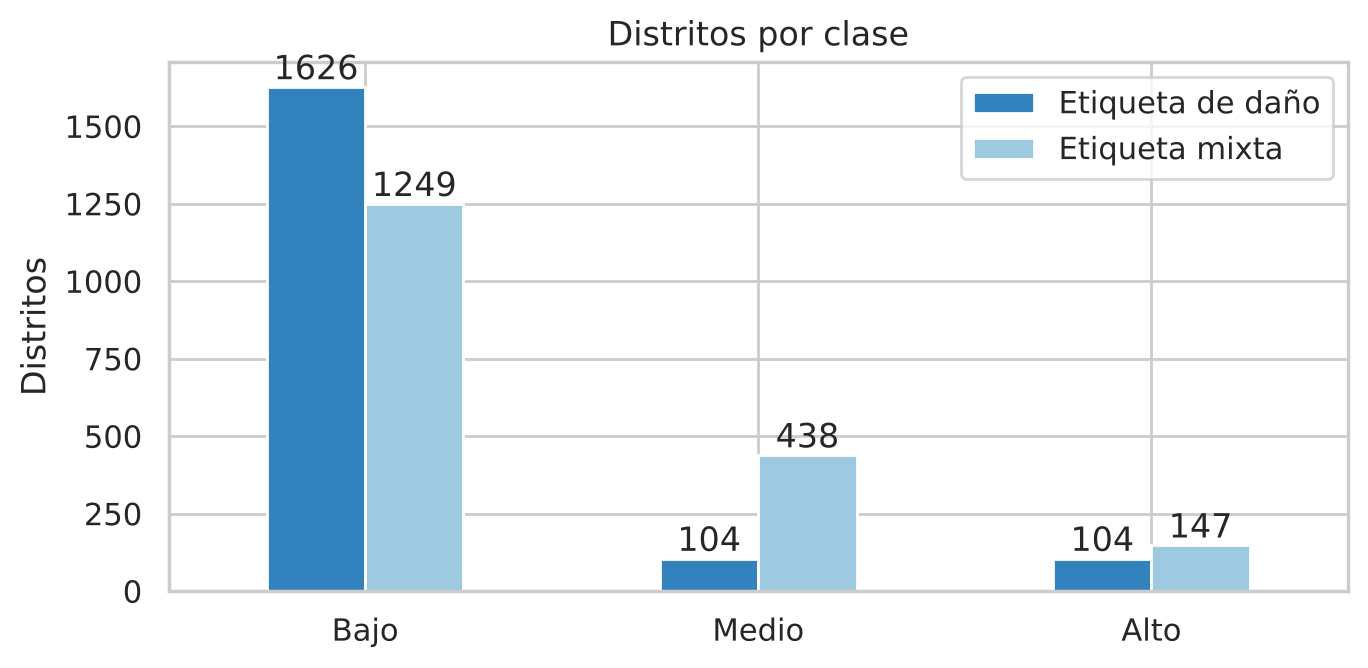

Distritos con huaicos en 2015-2020: 585 | de ellos sin ningún daño: 377
Distritos con daño en 2015-2020: 208 | con corte en P75 quedarían 52 Alto aprox.
Exactitud de predecir siempre 'Bajo': 0.887


In [ ]:
conteo = pd.DataFrame({"Etiqueta de daño": df["nivel_dano"].value_counts().reindex(ORDEN),
                       "Etiqueta mixta": df["nivel_dano_alt"].value_counts().reindex(ORDEN)})
ax = conteo.plot.bar(figsize=(7, 3.5), rot=0, color=["#3182bd", "#9ecae1"])
for c in ax.containers:
    ax.bar_label(c)
ax.set_ylabel("Distritos"); ax.set_title("Distritos por clase")
plt.tight_layout(); plt.show()

con_h = df["huaicos_2015_2020"] > 0
con_d = df["indice_dano"] > 0
print(f"Distritos con huaicos en 2015-2020: {con_h.sum()} | de ellos sin ningún daño: {(con_h & ~con_d).sum()}")
print(f"Distritos con daño en 2015-2020: {con_d.sum()} | con corte en P75 quedarían {int(np.ceil(con_d.sum() * 0.25))} Alto aprox.")
print(f"Exactitud de predecir siempre 'Bajo': {(y == 'Bajo').mean():.3f}")

**Decisión:** la clase Bajo domina, así que la exactitud no sirve como métrica: un modelo que siempre dice "Bajo" ya la obtiene alta. Por eso se usan **F1 macro** y **recall de Alto**, y se balancea el entrenamiento (SMOTE-NC o class_weight, Experimento 5). Muchos distritos tienen huaicos sin daño, por lo que contar huaicos en la etiqueta mezclaría frecuencia con daño. Por eso la etiqueta principal usa solo medidas de daño.

## B.2 Asimetría de las variables → transformación ln(1+x)

huaicos_2003_2014          78.6000
fallecidos_2003_2014       98.2000
damnificados_2003_2014     88.5000
viv_destruidas_2003_2014   89.3000
viv_afectadas_2003_2014    89.5000
has_destruidas_2003_2014   98.6000
Distritos con todos los daños 2003-2014 en cero: 1442

Asimetría (skewness) antes y después de ln(1+x):
                          original  ln(1+x)
huaicos_2003_2014           3.9500   2.0800
fallecidos_2003_2014       16.0300   8.7800
damnificados_2003_2014     26.7600   3.2200
viv_afectadas_2003_2014    19.5500   3.7000
has_destruidas_2003_2014   26.2300  10.7900


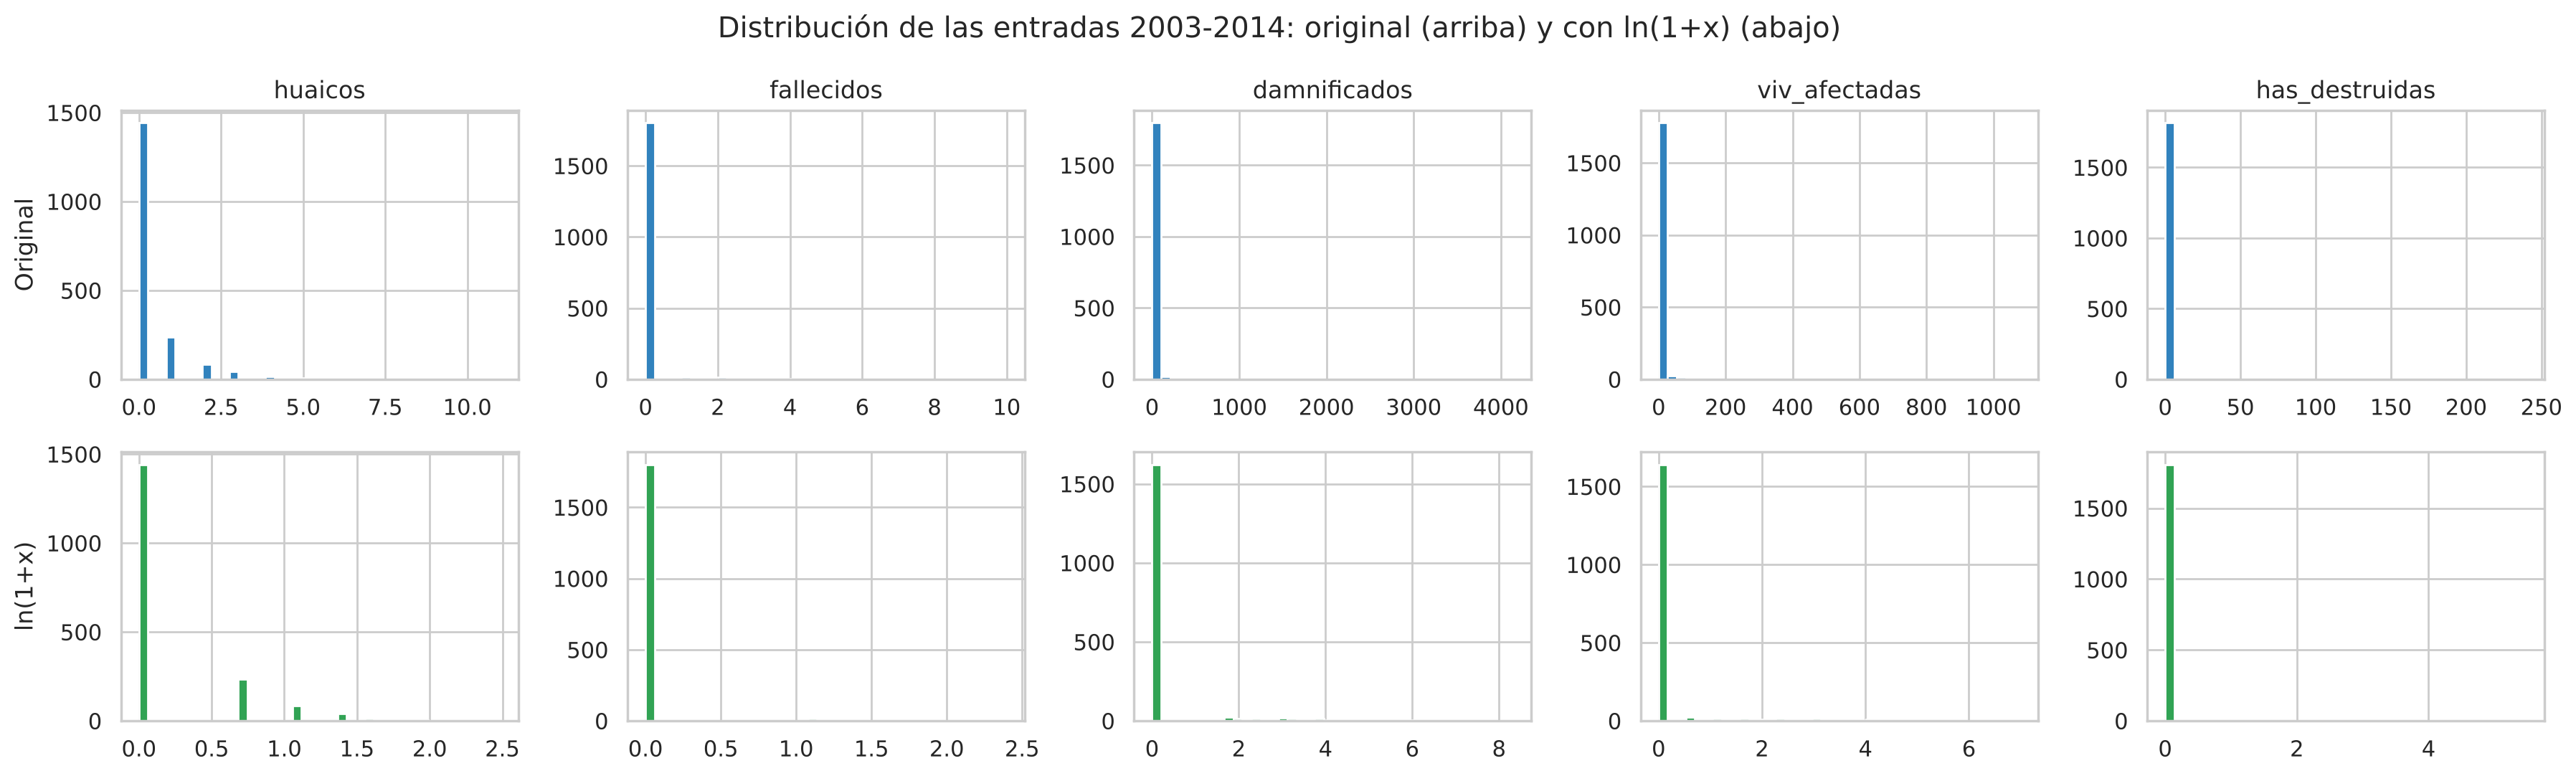

In [ ]:
ceros = (df[DANO_HIST] == 0).mean().rename("% de distritos en cero") * 100
print(ceros.round(1).to_string())
print("Distritos con todos los daños 2003-2014 en cero:", int((df[DANO_HIST].sum(axis=1) == 0).sum()))
print("\nAsimetría (skewness) antes y después de ln(1+x):")
print(pd.DataFrame({"original": df[NUM_LOG].skew(), "ln(1+x)": np.log1p(df[NUM_LOG]).skew()}).round(2))

fig, ejes = plt.subplots(2, len(NUM_LOG), figsize=(18, 5.5))
for j, c in enumerate(NUM_LOG):
    ejes[0, j].hist(df[c], bins=40, color="#3182bd"); ejes[0, j].set_title(c.replace("_2003_2014", ""))
    ejes[1, j].hist(np.log1p(df[c]), bins=40, color="#31a354")
ejes[0, 0].set_ylabel("Original"); ejes[1, 0].set_ylabel("ln(1+x)")
fig.suptitle("Distribución de las entradas 2003-2014: original (arriba) y con ln(1+x) (abajo)")
plt.tight_layout(); plt.show()

**Decisión:** las variables de daño tienen muchos ceros y unos pocos valores muy grandes. Sin transformarlas, la distancia de KNN y los coeficientes de la Regresión quedarían dominados por esos pocos distritos. ln(1+x) reduce la asimetría y conserva el cero; luego se estandariza. En `fallecidos` y `has_destruidas` la asimetría sigue alta después de la transformación porque el 98 % de los distritos está en cero; con tan pocos valores distintos de cero, ninguna transformación la elimina (una alternativa sería convertirlas en indicadores 0/1).

## B.3 Valores extremos → no se eliminan

In [ ]:
def n_atipicos(s):
    q1, q3 = s.quantile([0.25, 0.75])
    return int(((s < q1 - 1.5 * (q3 - q1)) | (s > q3 + 1.5 * (q3 - q1))).sum())

print(pd.DataFrame({"P25": df[NUM_LOG].quantile(0.25), "P75": df[NUM_LOG].quantile(0.75),
                    "Atípicos según IQR": {c: n_atipicos(df[c]) for c in NUM_LOG},
                    "Distritos con valor > 0": (df[NUM_LOG] > 0).sum()}))
print("\nDistritos con más damnificados 2003-2014:")
print(df.nlargest(5, "damnificados_2003_2014")[["departamento", "distrito", "damnificados_2003_2014", "huaicos_2003_2014"]].to_string(index=False))

                            P25    P75  Atípicos según IQR  \
huaicos_2003_2014        0.0000 0.0000                 392   
fallecidos_2003_2014     0.0000 0.0000                  33   
damnificados_2003_2014   0.0000 0.0000                 211   
viv_afectadas_2003_2014  0.0000 0.0000                 193   
has_destruidas_2003_2014 0.0000 0.0000                  26   

                          Distritos con valor > 0  
huaicos_2003_2014                             392  
fallecidos_2003_2014                           33  
damnificados_2003_2014                        211  
viv_afectadas_2003_2014                       193  
has_destruidas_2003_2014                       26  

Distritos con más damnificados 2003-2014:
departamento   distrito  damnificados_2003_2014  huaicos_2003_2014
       CUSCO    OROPESA               4142.0000             3.0000
        LIMA LURIGANCHO               1813.0000             1.0000
       JUNIN PICHANAQUI               1750.0000             4.0000
    

**Decisión:** como P25 = P75 = 0, el rango intercuartílico es cero y la regla IQR marca como "atípico" a **todo distrito con algún registro** (las dos últimas columnas coinciden). Aplicarla eliminaría todo el historial de huaicos. Además, los valores extremos son eventos reales registrados por el INDECI, no errores de digitación, y son justamente los distritos que interesa detectar. Por eso se mantienen y su efecto se reduce con ln(1+x).

## B.4 Variables por clase (solo train)

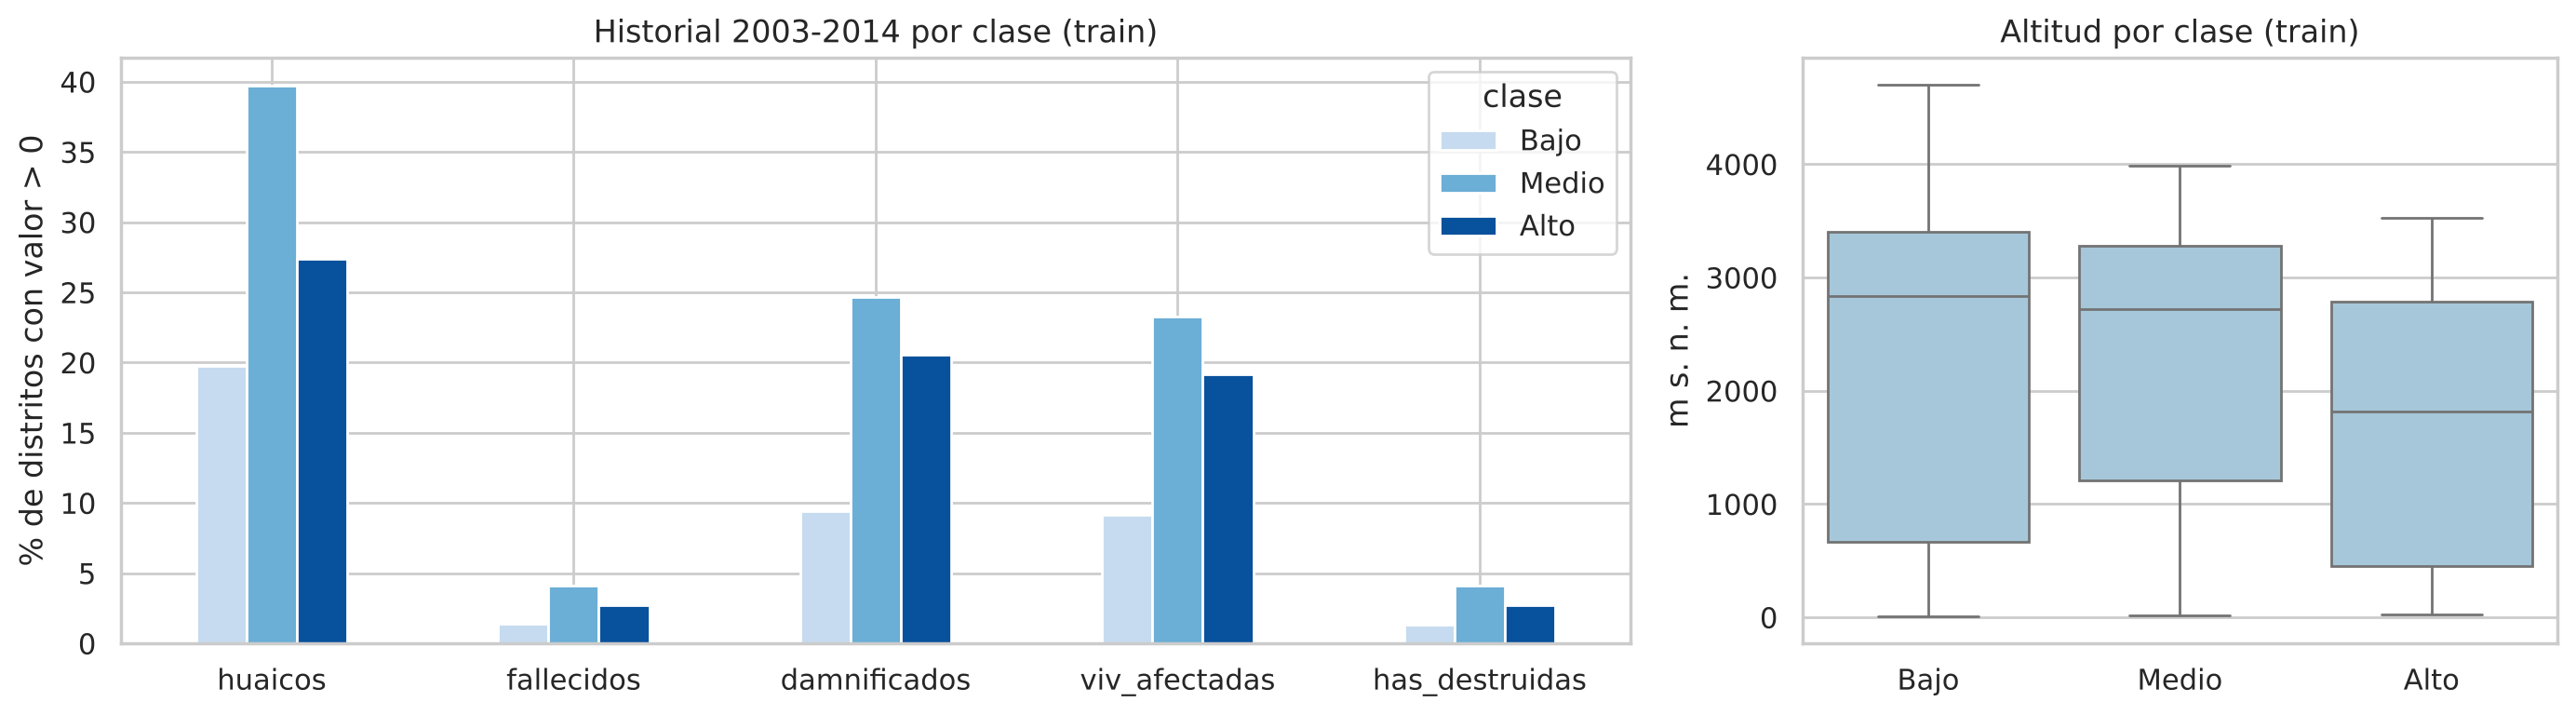

% de distritos con valor > 0 en 2003-2014, por clase (train):
       huaicos  fallecidos  damnificados  viv_afectadas  has_destruidas
clase                                                                  
Bajo   19.8000      1.4000        9.4000         9.1000          1.3000
Medio  39.7000      4.1000       24.7000        23.3000          4.1000
Alto   27.4000      2.7000       20.5000        19.2000          2.7000

Media de ln(1+x) por clase (train):
       huaicos_2003_2014  fallecidos_2003_2014  damnificados_2003_2014  \
clase                                                                    
Bajo              0.1790                0.0150                  0.3110   
Medio             0.4740                0.0530                  0.8770   
Alto              0.2980                0.0250                  0.9100   

       viv_afectadas_2003_2014  has_destruidas_2003_2014  
clase                                                     
Bajo                    0.2370                    0.

In [ ]:
tr = Xtr.assign(clase=pd.Categorical(ytr, ORDEN, ordered=True))
pct = (tr[NUM_LOG].gt(0).groupby(tr["clase"], observed=True).mean() * 100)
pct.columns = [c.replace("_2003_2014", "") for c in pct.columns]

fig, ejes = plt.subplots(1, 2, figsize=(14, 4), gridspec_kw={"width_ratios": [2, 1]})
pct.T.plot.bar(ax=ejes[0], rot=0, color=["#c6dbef", "#6baed6", "#08519c"])
ejes[0].set_ylabel("% de distritos con valor > 0"); ejes[0].set_title("Historial 2003-2014 por clase (train)")
sns.boxplot(x=tr["clase"], y=tr["altitud"], ax=ejes[1], color="#9ecae1")
ejes[1].set_title("Altitud por clase (train)"); ejes[1].set_xlabel(""); ejes[1].set_ylabel("m s. n. m.")
plt.tight_layout(); plt.show()

print("% de distritos con valor > 0 en 2003-2014, por clase (train):")
print(pct.round(1))
print("\nMedia de ln(1+x) por clase (train):")
print(np.log1p(tr[NUM_LOG]).groupby(tr["clase"], observed=True).mean().round(3))
print("\nAltitud por clase (train):")
print(tr.groupby("clase", observed=True)["altitud"].describe()[["25%", "50%", "75%"]].round(0))
print("\nProporción de cada clase por región (train, %):")
print((pd.crosstab(tr["region_natural"], tr["clase"], normalize="index") * 100).round(1))

**Lectura:** como la mayoría de distritos tiene historial en cero, se compara el **porcentaje de distritos con algún registro** en cada clase, en lugar de la mediana (que es 0 en las tres).
- **La geografía separa las clases:** la altitud mediana de los distritos Alto (1 817 m) es mucho menor que la de Bajo (2 836 m) y Medio (2 720 m). Por región, el 10,8 % de los distritos de Costa es Alto, frente al 1,0 % en Selva Baja.
- **El historial separa daño de no daño, pero no Medio de Alto:** los distritos con daño en 2015-2020 tienen más historial que los Bajo (huaicos previos: 19,8 % en Bajo frente a 39,7 % en Medio y 27,4 % en Alto), pero la relación **no es monótona**: los Medio tienen más historial que los Alto. Por eso se anticipa que distinguir Medio de Alto será lo más difícil. Una posible explicación es que el daño de 2015-2020 se concentró en eventos que afectaron zonas con poco historial registrado, como El Niño Costero de 2017 (de los 46 grupos de reportes con mismo distrito y fecha, 18 son de 2017, el año con más).

## B.5 Correlación de Spearman y VIF → exclusión de `viv_destruidas`
Spearman mide relaciones monótonas, por lo que es adecuado para variables asimétricas. El VIF mide cuánto se explica una variable a partir de las demás (VIF > 5 indica colinealidad alta). Se calcula con las variables ya transformadas, como entran al modelo.

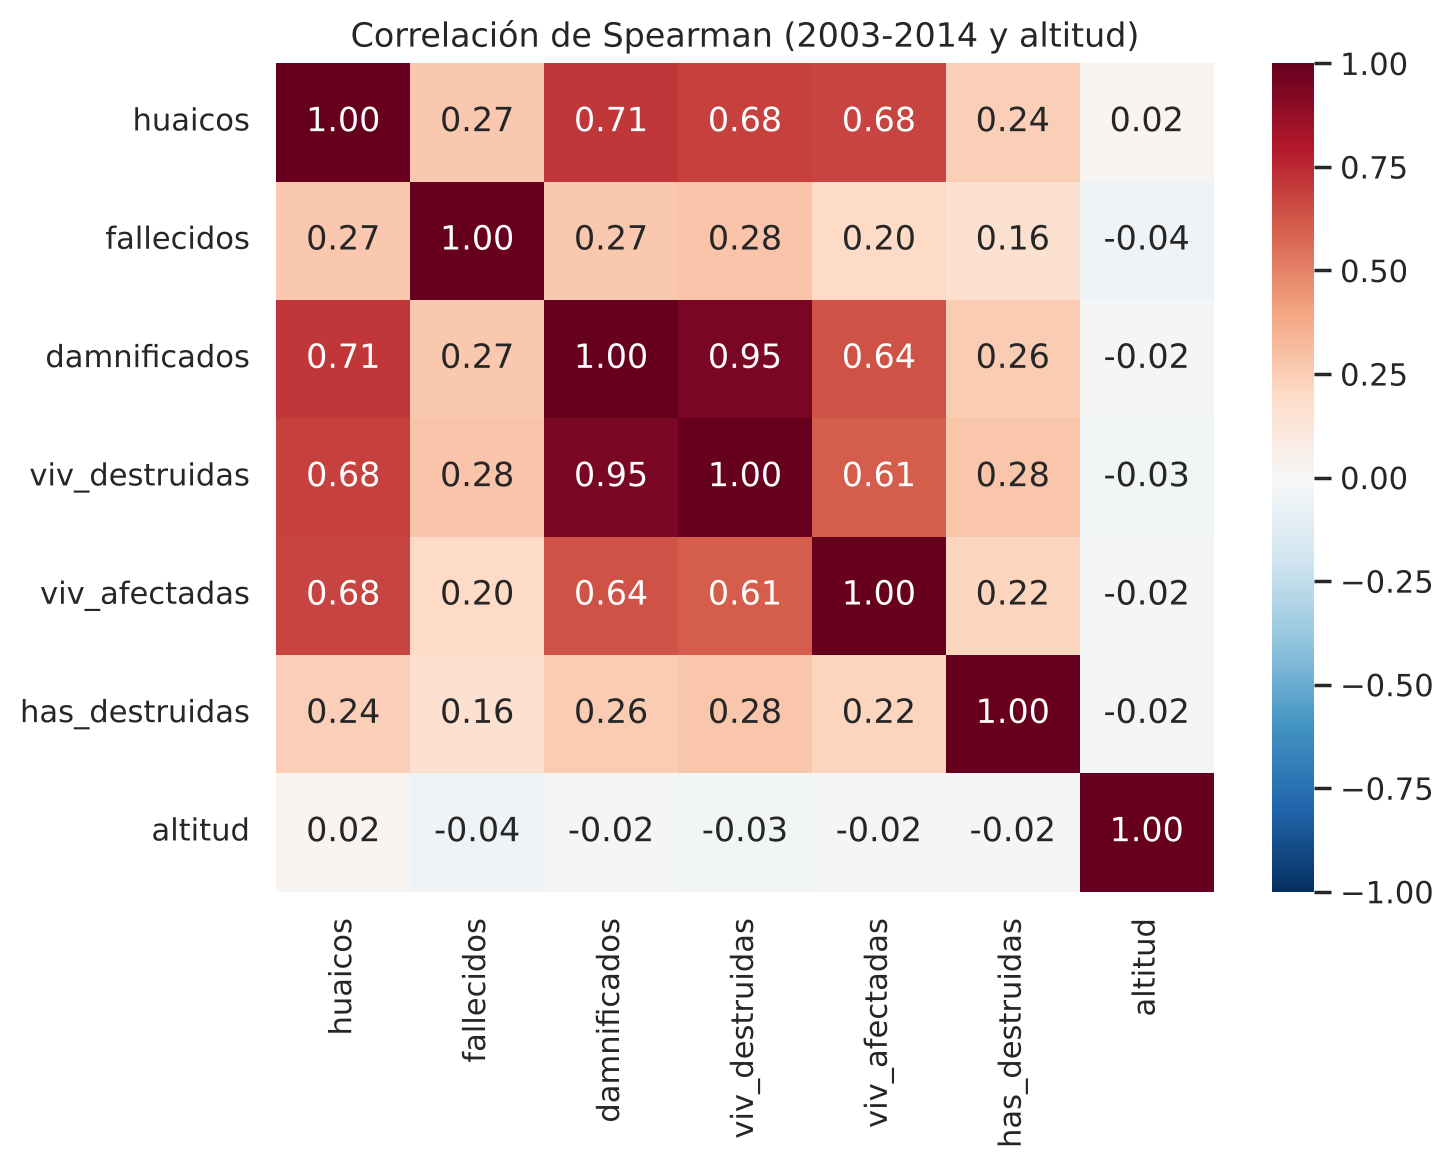

VIF con todas las variables de daño (ln 1+x):


huaicos_2003_2014           2.1500
fallecidos_2003_2014        1.1600
damnificados_2003_2014     10.3600
viv_destruidas_2003_2014    9.2100
viv_afectadas_2003_2014     2.0700
has_destruidas_2003_2014    1.1300

VIF de las variables finales (sin viv_destruidas, con altitud y región; Costa = referencia):
huaicos_2003_2014          2.1600
fallecidos_2003_2014       1.1400
damnificados_2003_2014     2.4200
viv_afectadas_2003_2014    2.0400
has_destruidas_2003_2014   1.1400
altitud                    7.4200
SELVA ALTA                 1.6100
SELVA BAJA                 1.3000
SIERRA                     8.4900


In [ ]:
corr = df[DANO_HIST + ["altitud"]].corr(method="spearman")
plt.figure(figsize=(7.5, 6))
etq = [c.replace("_2003_2014", "") for c in corr.columns]
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, xticklabels=etq, yticklabels=etq)
plt.title("Correlación de Spearman (2003-2014 y altitud)"); plt.tight_layout(); plt.show()

def vif(D):
    D = D.astype(float)
    return pd.Series({c: 1 / (1 - LinearRegression().fit(D.drop(columns=c), D[c]).score(D.drop(columns=c), D[c]))
                      for c in D}).round(2)

print("VIF con todas las variables de daño (ln 1+x):")
print(vif(np.log1p(df[DANO_HIST])).to_string())

geo_vif = pd.concat([np.log1p(df[NUM_LOG]), df[["altitud"]],
                     pd.get_dummies(df["region_natural"], drop_first=True)], axis=1)
print("\nVIF de las variables finales (sin viv_destruidas, con altitud y región; Costa = referencia):")
print(vif(geo_vif).to_string())

**Decisión:** `damnificados` y `viv_destruidas` tienen VIF altos, es decir, aportan casi la misma información. Se excluye una de las dos; se conserva `damnificados` porque mide el impacto sobre las personas y es más fácil de interpretar. Sin `viv_destruidas`, todas las variables de daño quedan con VIF ≤ 2,42. La colinealidad afecta sobre todo a la Regresión Logística (coeficientes inestables); a KNN y al Árbol casi no les afecta, pero quitar una variable redundante también simplifica su interpretación. La altitud y la región Sierra también están relacionadas entre sí (la Sierra es alta), pero describen aspectos distintos del territorio; se mantienen ambas y el Experimento 3 mide cuánto aporta cada una.

## B.6 Información mutua con la etiqueta (solo train)
Mide cuánta información aporta cada variable sobre la clase, sin suponer una relación lineal. Las variables de daño son **conteos** con muchos ceros, así que se tratan como **discretas**: el estimador para variables continuas (basado en vecinos) funciona mal cuando la mayoría de valores son iguales. La altitud se trata como continua.

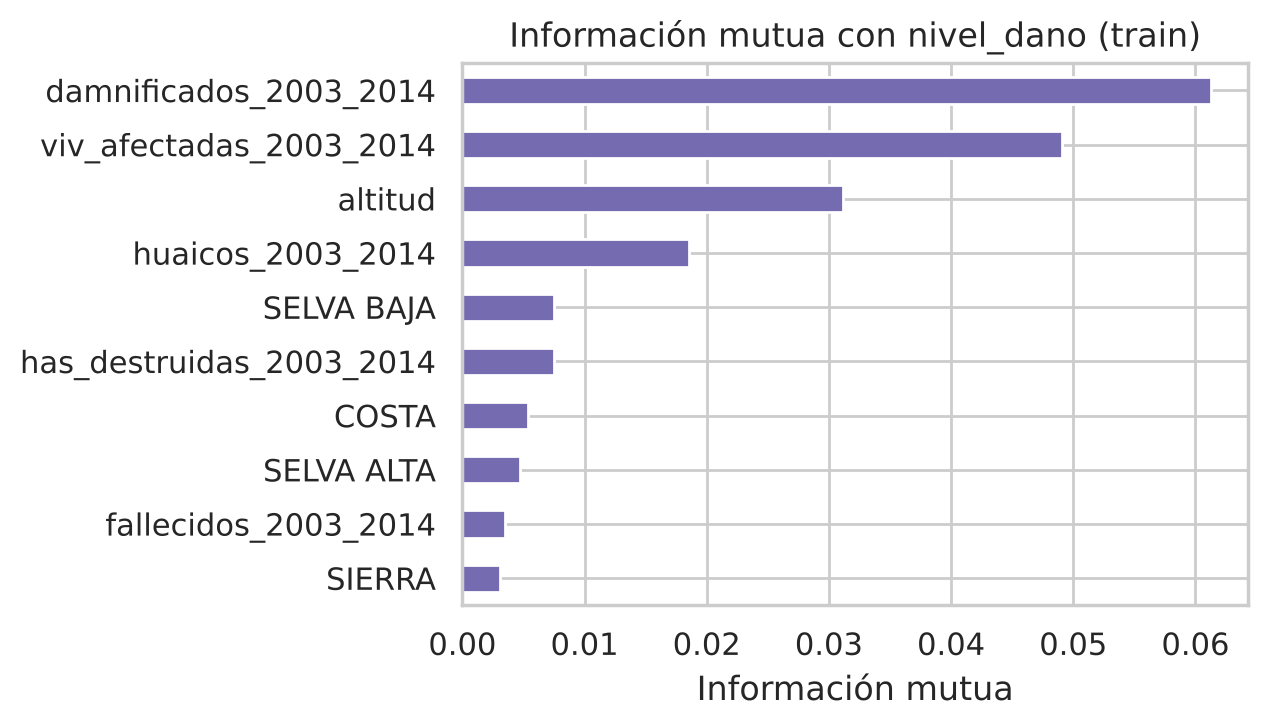

damnificados_2003_2014     0.0612
viv_afectadas_2003_2014    0.0491
altitud                    0.0312
huaicos_2003_2014          0.0186
SELVA BAJA                 0.0075
has_destruidas_2003_2014   0.0075
COSTA                      0.0053
SELVA ALTA                 0.0047
fallecidos_2003_2014       0.0035
SIERRA                     0.0031


In [ ]:
Xmi = pd.concat([Xtr[NUM_LOG].round().astype(int), Xtr[["altitud"]], pd.get_dummies(Xtr["region_natural"]).astype(int)], axis=1)
discretas = [True] * len(NUM_LOG) + [False] + [True] * (Xmi.shape[1] - len(NUM_LOG) - 1)
MI = pd.Series(mutual_info_classif(Xmi, ytr, discrete_features=discretas, random_state=SEED),
               index=Xmi.columns).sort_values()
MI.plot.barh(figsize=(6.5, 3.8), color="#756bb1", title="Información mutua con nivel_dano (train)")
plt.xlabel("Información mutua"); plt.tight_layout(); plt.show()
print(MI.sort_values(ascending=False).round(4).to_string())

**Lectura:** las variables con más información mutua son el historial de damnificados (0,061) y de viviendas afectadas (0,049), seguidas de la altitud (0,031). Todos los valores son bajos: **ninguna variable por sí sola separa bien las tres clases**, lo que anticipa un rendimiento modesto de cualquier modelo. La información mutua mide la relación de cada variable por separado; los experimentos de la Parte C miden su aporte dentro de los modelos.

## B.7 Decisiones que no requieren EDA adicional
- **No se usa PCA:** hay solo 7 variables de entrada y uno de los objetivos es interpretar el aporte de cada una; las componentes principales mezclarían variables y perderían esa lectura.
- **No hay valores nulos que imputar en las entradas:** un distrito sin huaicos registrados tiene 0 daños; solo se imputó la altitud de los distritos marcados en `altitud_imputada`.

# Parte C. Modelado y experimentos

## C.1 Pipeline
ln(1+x) → estandarización → SMOTE-NC → one-hot de la región → modelo. Se usa `imblearn.pipeline.Pipeline` para que el sobremuestreo se aplique **solo** al entrenamiento de cada pliegue y nunca a los datos de validación.

Las grillas de hiperparámetros incluyen valores a ambos lados de los óptimos esperados, y en C.11 se verifica si algún óptimo queda en el borde.

**Decisiones de diseño:**
- **SMOTE-NC para los tres modelos:** se fija de antemano porque prioriza detectar la clase Alto y porque KNN no admite `class_weight`; así los tres modelos se comparan con el mismo tratamiento del desbalance. El Experimento 5 evalúa esta decisión.
- **Selección de hiperparámetros por F1 macro:** es la métrica principal; el recall de Alto se usa como métrica de control. Por eso, un aumento de F1 macro que reduzca mucho el recall de Alto no se considera una mejora para el objetivo del trabajo.
- **One-hot sin escalar:** las columnas de la región (0/1) entran a KNN sin estandarizar, lo que fija implícitamente su peso en la distancia frente a las variables numéricas estandarizadas.

In [ ]:
def _a_float(a):
    return np.asarray(a, dtype=float)

def crear_pipeline(modelo, usar_altitud=True, usar_region=True, balanceo=None):
    pasos = [("log_esc", make_pipeline(FunctionTransformer(np.log1p), StandardScaler()), NUM_LOG)]
    n_num = len(NUM_LOG)
    if usar_altitud:
        pasos.append(("esc", StandardScaler(), ["altitud"])); n_num += 1
    if usar_region:
        pasos.append(("cat", "passthrough", ["region_natural"]))
    etapas = [("escala", ColumnTransformer(pasos))]
    if balanceo == "smote":
        etapas.append(("smote", SMOTENC(categorical_features=[n_num], random_state=SEED) if usar_region
                                else SMOTE(random_state=SEED)))
    if usar_region:
        etapas.append(("onehot", ColumnTransformer(
            [("oh", OneHotEncoder(handle_unknown="ignore", sparse_output=False), [n_num])],
            remainder="passthrough", sparse_threshold=0)))
    etapas += [("a_float", FunctionTransformer(_a_float)), ("modelo", modelo)]
    return Pipeline(etapas)

def nombres_features(pipe, usar_altitud=True, usar_region=True):
    num = NUM_LOG + (["altitud"] if usar_altitud else [])
    if usar_region:
        cats = pipe.named_steps["onehot"].named_transformers_["oh"].categories_[0]
        return [f"region={c}" for c in cats] + num
    return num

FABRICAS = {
    "KNN": lambda **kw: KNeighborsClassifier(**kw),
    "Arbol": lambda **kw: DecisionTreeClassifier(criterion="gini", random_state=SEED, **kw),
    "Regresion": lambda **kw: LogisticRegression(max_iter=2000, **kw),
}
GRILLAS = {
    "KNN": {"modelo__n_neighbors": [3, 5, 7, 9, 11, 15, 21, 31], "modelo__weights": ["uniform", "distance"]},
    "Arbol": {"modelo__max_depth": [2, 3, 5, 7, 10, 15, None], "modelo__min_samples_leaf": [1, 5, 10, 20, 50, 100, 150, 200, 300, 400, 600]},
    "Regresion": {"modelo__C": [0.001, 0.01, 0.1, 1, 10, 100]},
}

def recall_alto(y_true, y_pred):
    return recall_score(y_true, y_pred, labels=["Alto"], average="macro", zero_division=0)

def f1_clase(clase):
    return make_scorer(lambda yt, yp: f1_score(yt, yp, labels=[clase], average="macro", zero_division=0))

SCORING = {"f1m": "f1_macro", "rec_alto": make_scorer(recall_alto),
           "f1_medio": f1_clase("Medio"), "f1_alto": f1_clase("Alto"), "mcc": make_scorer(matthews_corrcoef)}
METRICAS = [("f1m", "F1 macro"), ("rec_alto", "Recall Alto"), ("f1_medio", "F1 Medio"), ("f1_alto", "F1 Alto")]
CV_REP = RepeatedStratifiedKFold(n_splits=5, n_repeats=5, random_state=SEED)

def cv_rep(pipe, Xe, ye, train=False):
    r = cross_validate(pipe, Xe, ye, cv=CV_REP, scoring=SCORING, n_jobs=-1, return_train_score=train)
    out = {k: r[f"test_{k}"] for k in SCORING}
    if train:
        out["f1m_train"] = r["train_f1m"]
    return out

def cv_anidada(nombre, Xe, ye, usar_altitud=True, usar_region=True, balanceo="smote", extra=None):
    modelo = FABRICAS[nombre](**(extra or {}))
    pipe = crear_pipeline(modelo, usar_altitud, usar_region, balanceo)
    gs = GridSearchCV(pipe, GRILLAS[nombre], cv=StratifiedKFold(5, shuffle=True, random_state=SEED),
                      scoring="f1_macro", n_jobs=1)
    return cv_rep(gs, Xe, ye)

def tabla_cv(res):
    return pd.DataFrame({n: {"F1 macro (media)": r["f1m"].mean(), "F1 macro (desv.)": r["f1m"].std(),
                             "Recall Alto (media)": r["rec_alto"].mean(), "Recall Alto (desv.)": r["rec_alto"].std(),
                             "F1 Medio": r["f1_medio"].mean(), "F1 Alto": r["f1_alto"].mean(), "MCC": r["mcc"].mean()}
                         for n, r in res.items()}).T

K_PLIEGUES, R_REPETICIONES = 5, 5

def t_corregido_p(a, b, alternativa="two-sided"):
    # Prueba t corregida para CV repetida (Nadeau y Bengio, 2003).
    # Los 25 resultados no son independientes porque los conjuntos de entrenamiento se superponen;
    # la corrección agrega n_test/n_train a la varianza para no sobreestimar la significancia.
    d = np.asarray(a, dtype=float) - np.asarray(b, dtype=float)
    n = K_PLIEGUES * R_REPETICIONES
    var = d.var(ddof=1)
    if var == 0:
        return 1.0
    ratio = 1 / (K_PLIEGUES - 1)                     # n_test / n_train con 5 pliegues = 1/4
    t_est = d.mean() / np.sqrt((1 / n + ratio) * var)
    if alternativa == "greater":
        return float(dist_t.sf(t_est, df=n - 1))
    return float(2 * dist_t.sf(abs(t_est), df=n - 1))

def holm(pvals):
    # Corrección de Holm-Bonferroni para varias pruebas a la vez (controla los falsos positivos)
    p = np.asarray(pvals, dtype=float); m = len(p); orden = np.argsort(p)
    ajust = np.empty(m); acum = 0.0
    for i, j in enumerate(orden):
        acum = max(acum, min(1.0, (m - i) * p[j])); ajust[j] = acum
    return ajust

def wilcoxon_p(a, b, alternativa="two-sided"):
    a, b = np.asarray(a), np.asarray(b)
    if np.allclose(a - b, 0):
        return 1.0
    return wilcoxon(a, b, alternative=alternativa).pvalue

def entrenar_experimento(Xe, ye, verbose=False):
    cv = StratifiedKFold(5, shuffle=True, random_state=SEED)
    ajustados, params = {"Base": crear_pipeline(DummyClassifier(strategy="most_frequent")).fit(Xe, ye)}, {}
    for n in MODELOS:
        gs = GridSearchCV(crear_pipeline(FABRICAS[n](), balanceo="smote"), GRILLAS[n],
                          cv=cv, scoring="f1_macro", n_jobs=-1).fit(Xe, ye)
        ajustados[n] = gs.best_estimator_
        params[n] = {k.replace("modelo__", ""): v for k, v in gs.best_params_.items()}
        if verbose:
            print(f"{n}: {params[n]} | F1 macro (CV de la búsqueda) = {gs.best_score_:.4f}")
    return ajustados, params

def evaluar_test(modelos, Xe, ye):
    filas, preds = [], {}
    for n, m in modelos.items():
        p = m.predict(Xe); preds[n] = p
        filas.append({"Modelo": n, "F1 macro": f1_score(ye, p, average="macro"),
                      "Recall Alto": recall_alto(ye, p),
                      "Precision Alto": precision_score(ye, p, labels=["Alto"], average="macro", zero_division=0),
                      "F1 Alto": f1_score(ye, p, labels=["Alto"], average="macro", zero_division=0),
                      "F1 Medio": f1_score(ye, p, labels=["Medio"], average="macro", zero_division=0),
                      "Exactitud (ref.)": accuracy_score(ye, p)})
    return pd.DataFrame(filas).set_index("Modelo"), preds

## C.2 Experimento 1: Comparación de algoritmos
**Clasificador base:** `DummyClassifier(strategy="most_frequent")`, que siempre predice la clase mayoritaria (Bajo). "Superar a la base" significa obtener un F1 macro mayor que el suyo, comparando CV con CV y test con test.

Se eligen los hiperparámetros con `GridSearchCV` (5 pliegues, F1 macro) sobre el train y se estima su rendimiento con CV repetida 5×5. También se reporta el F1 en entrenamiento: una brecha grande entre train y validación indica sobreajuste. **Importante:** aquí los mismos datos sirven para elegir los hiperparámetros y para estimar el rendimiento, así que estos valores de CV son **algo optimistas**. Las cifras de CV que se reportan como estimación principal son las de la **CV anidada** (Experimento 2). Esta tabla se usa para el test y como referencia.

*Nota:* con `weights="distance"`, KNN reconoce casi siempre a sus propios puntos de entrenamiento (distancia 0), por lo que su F1 de train sale alto por construcción; para KNN la brecha no se interpreta igual que en los otros modelos.

In [ ]:
AJ, PAR = entrenar_experimento(Xtr, ytr, verbose=True)
RES = {n: cv_rep(AJ[n], Xtr, ytr, train=True) for n in ["Base"] + MODELOS}
TABLA_CV = tabla_cv(RES)
TABLA_CV["F1 macro train (media)"] = [RES[n]["f1m_train"].mean() for n in TABLA_CV.index]
TABLA_CV["Brecha train - CV"] = TABLA_CV["F1 macro train (media)"] - TABLA_CV["F1 macro (media)"]
TABLA_CV

KNN: {'n_neighbors': 9, 'weights': 'distance'} | F1 macro (CV de la búsqueda) = 0.3298


Arbol: {'max_depth': 3, 'min_samples_leaf': 300} | F1 macro (CV de la búsqueda) = 0.3774


Regresion: {'C': 0.01} | F1 macro (CV de la búsqueda) = 0.3545


,F1 macro (media),F1 macro (desv.),Recall Alto (media),Recall Alto (desv.),F1 Medio,F1 Alto,MCC,F1 macro train (media),Brecha train - CV
Base,0.3132,0.0003,0.0000,0.0000,0.0000,0.0000,0.0000,0.3132,0.0000
KNN,0.3191,0.0292,0.3318,0.1292,0.1041,0.1448,0.0751,0.9676,0.6484
Arbol,0.3683,0.0738,0.4095,0.1418,0.2080,0.1493,0.1175,0.3826,0.0142
Regresion,0.3552,0.0268,0.3863,0.0913,0.1583,0.1667,0.1070,0.3690,0.0138


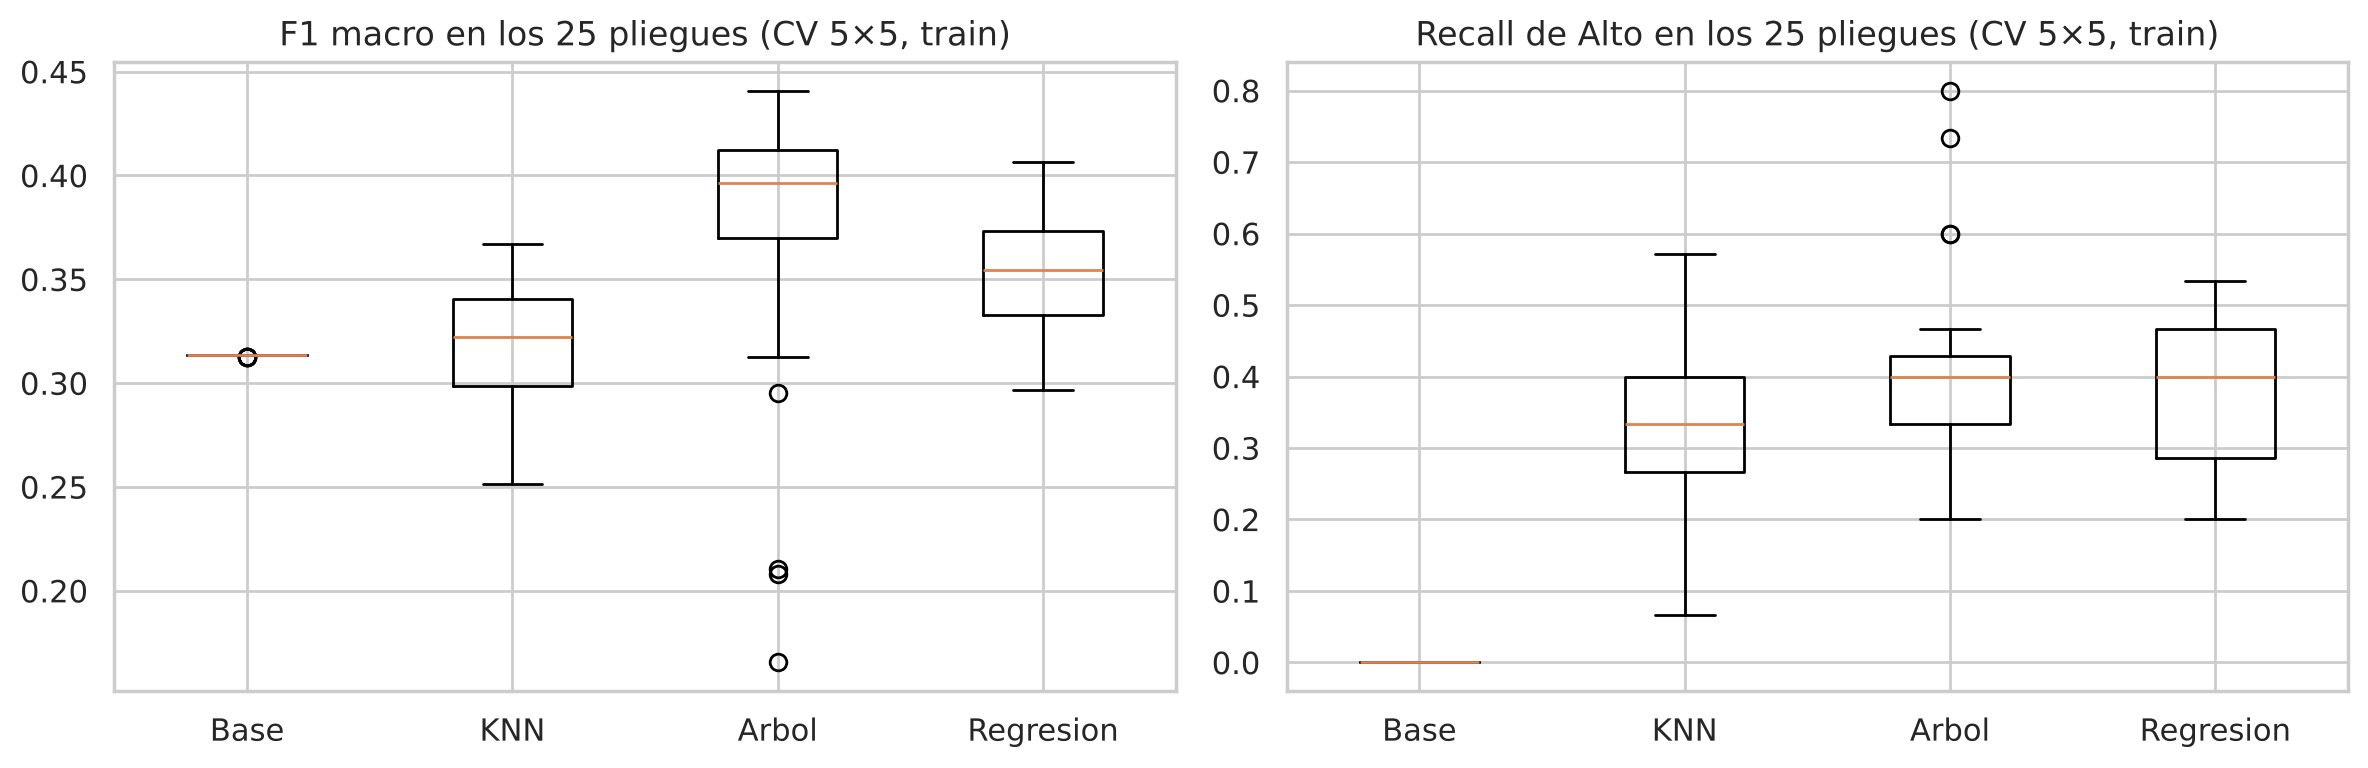

In [ ]:
fig, ejes = plt.subplots(1, 2, figsize=(12, 4))
for ax, met, tit in zip(ejes, ["f1m", "rec_alto"], ["F1 macro", "Recall de Alto"]):
    ax.boxplot([RES[n][met] for n in ["Base"] + MODELOS])
    ax.set_xticks(range(1, len(MODELOS) + 2)); ax.set_xticklabels(["Base"] + MODELOS)
    ax.set_title(f"{tit} en los 25 pliegues (CV 5×5, train)")
plt.tight_layout(); plt.show()

In [ ]:
TEST, PRED = evaluar_test({n: AJ[n] for n in ["Base"] + MODELOS}, Xte, yte)
TEST

,F1 macro,Recall Alto,Precision Alto,F1 Alto,F1 Medio,Exactitud (ref.)
Modelo,,,,,,
Base,0.3135,0.0000,0.0000,0.0000,0.0000,0.8875
KNN,0.2966,0.2581,0.0741,0.1151,0.0838,0.5263
Arbol,0.3505,0.3548,0.1048,0.1618,0.0563,0.7005
Regresion,0.3542,0.3548,0.1009,0.1571,0.1507,0.5989


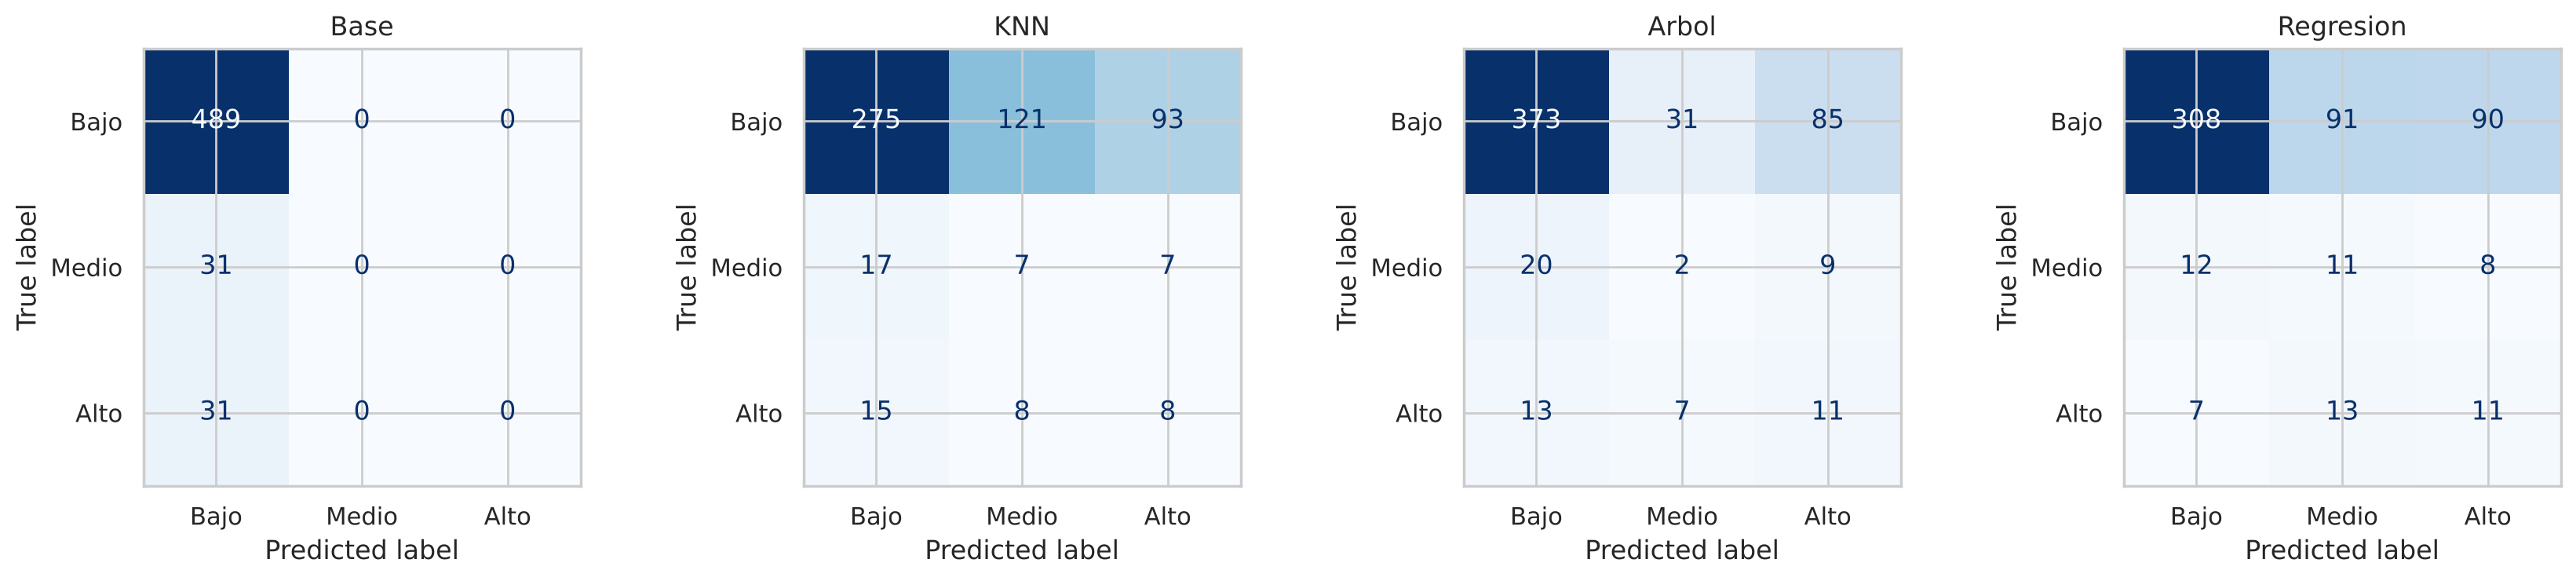

KNN: detecta 8 de 31 distritos Alto del test
Arbol: detecta 11 de 31 distritos Alto del test
Regresion: detecta 11 de 31 distritos Alto del test


In [ ]:
fig, ejes = plt.subplots(1, 4, figsize=(17, 3.8))
for ax, n in zip(ejes, ["Base"] + MODELOS):
    ConfusionMatrixDisplay(confusion_matrix(yte, PRED[n], labels=ORDEN), display_labels=ORDEN).plot(
        ax=ax, cmap="Blues", colorbar=False)
    ax.set_title(n)
plt.tight_layout(); plt.show()
n_alto = int((yte == "Alto").sum())
for n in MODELOS:
    print(f"{n}: detecta {int(((yte == 'Alto') & (PRED[n] == 'Alto')).sum())} de {n_alto} distritos Alto del test")

**Lectura del Experimento 1:**
- El Árbol elegido es **muy simple** (profundidad 3 y al menos 300 casos por hoja): con pocos distritos Alto, generaliza mejor cuando se le impide memorizar el entrenamiento.
- En CV, el Árbol (0,3683) y la Regresión (0,3552) superan a la base (0,3132); KNN apenas (0,3191). La brecha entre train y CV es pequeña en el Árbol y la Regresión (0,014 en ambos): no hay sobreajuste. En KNN la brecha (0,648) se debe al peso por distancia.
- En test, la Regresión (0,3542) y el Árbol (0,3505) superan a la base (0,3135) y **detectan 11 de los 31 distritos Alto** cada uno; KNN queda por debajo de la base (0,2966) y detecta 8.
- La **precisión de Alto es baja** (≈ 0,10): de cada 10 distritos que se marcan como Alto, aproximadamente 1 lo es. El Árbol casi no predice Medio (F1 de Medio en test 0,056).

## C.3 Experimento 2: Significancia (CV anidada + t corregido de Nadeau y Bengio)
En la CV anidada, los hiperparámetros se vuelven a elegir dentro de cada pliegue externo, así la estimación no usa los mismos datos para elegir y para evaluar. Los 25 pliegues son los mismos para todos los modelos, de modo que las diferencias son pareadas.

**Prueba estadística:** los 25 resultados de una CV 5×5 **no son independientes**, porque los conjuntos de entrenamiento se superponen entre pliegues. Una prueba t o de Wilcoxon común trataría esas 25 diferencias como independientes y daría p-valores demasiado pequeños. Por eso se usa la **prueba t corregida para CV repetida** (Nadeau y Bengio, 2003):

$$t = \frac{\bar d}{\sqrt{\left(\frac{1}{k\cdot r} + \frac{n_{test}}{n_{train}}\right)\hat\sigma^2_d}}, \qquad gl = k\cdot r - 1$$

con $k = 5$ pliegues, $r = 5$ repeticiones y $n_{test}/n_{train} = 1/4$. El término $n_{test}/n_{train}$ aumenta la varianza para compensar la dependencia. Como la hipótesis afirma que KNN y el Árbol son **mejores** que la Regresión, la prueba es **unilateral**. Se aplica al F1 macro y al recall de Alto (criterio de la hipótesis) y también al F1 de Medio y de Alto. El p de Wilcoxon se muestra solo como referencia: tiene el mismo problema de dependencia, por lo que no se usa para decidir.

Además se prueba la **dirección contraria** (¿la Regresión es mejor que KNN y el Árbol?), con corrección de Holm, para saber si se puede afirmar que la Regresión es superior.


In [ ]:
CONFIGS_GEO = [("Completo", True, True), ("Sin altitud", False, True), ("Sin región", True, False),
               ("Sin geografía", False, False)]
RES_GEO = {(m, c): cv_anidada(m, Xtr, ytr, usar_altitud=a, usar_region=r)
           for m in MODELOS for c, a, r in CONFIGS_GEO}

TABLA_ANIDADA = tabla_cv({m: RES_GEO[(m, "Completo")] for m in MODELOS})
TABLA_ANIDADA.loc["Base"] = TABLA_CV.loc["Base", TABLA_ANIDADA.columns]
TABLA_ANIDADA

,F1 macro (media),F1 macro (desv.),Recall Alto (media),Recall Alto (desv.),F1 Medio,F1 Alto,MCC
KNN,0.3151,0.0240,0.3408,0.1232,0.1074,0.1396,0.0699
Arbol,0.3508,0.0661,0.3646,0.1891,0.1766,0.1361,0.1026
Regresion,0.3536,0.0244,0.3979,0.1001,0.1596,0.1664,0.1094
Base,0.3132,0.0003,0.0000,0.0000,0.0000,0.0000,0.0000


In [ ]:
filas = []
for a in ["KNN", "Arbol"]:
    ra, rb = RES_GEO[(a, "Completo")], RES_GEO[("Regresion", "Completo")]
    for met, nom in METRICAS:
        filas.append({"Comparación": f"{a} > Regresion", "Métrica": nom,
                      "Media modelo": ra[met].mean(), "Media Regresión": rb[met].mean(),
                      "p t corregido (unilateral)": t_corregido_p(ra[met], rb[met], "greater"),
                      "p Wilcoxon (unilateral, ref.)": wilcoxon_p(ra[met], rb[met], "greater")})
SIGNIF = pd.DataFrame(filas)
SIGNIF["¿Significativo a favor (α=0,05)?"] = SIGNIF["p t corregido (unilateral)"] < 0.05
SIGNIF

,Comparación,Métrica,Media modelo,Media Regresión,p t corregido (unilateral),"p Wilcoxon (unilateral, ref.)","¿Significativo a favor (α=0,05)?"
0,KNN > Regresion,F1 macro,0.3151,0.3536,0.9744,1.0000,False
1,KNN > Regresion,Recall Alto,0.3408,0.3979,0.7167,0.9463,False
2,KNN > Regresion,F1 Medio,0.1074,0.1596,0.9517,0.9999,False
3,KNN > Regresion,F1 Alto,0.1396,0.1664,0.7697,0.9632,False
4,Arbol > Regresion,F1 macro,0.3508,0.3536,0.5274,0.3755,False
5,Arbol > Regresion,Recall Alto,0.3646,0.3979,0.6180,0.8331,False
6,Arbol > Regresion,F1 Medio,0.1766,0.1596,0.3666,0.1436,False
7,Arbol > Regresion,F1 Alto,0.1361,0.1664,0.8809,0.9979,False


In [ ]:
filas = []
for b in ["KNN", "Arbol"]:
    ra, rb = RES_GEO[("Regresion", "Completo")], RES_GEO[(b, "Completo")]
    for met, nom in METRICAS:
        filas.append({"Comparación": f"Regresion > {b}", "Métrica": nom,
                      "Diferencia de medias": ra[met].mean() - rb[met].mean(),
                      "p t corregido (unilateral)": t_corregido_p(ra[met], rb[met], "greater")})
INVERSA = pd.DataFrame(filas)
INVERSA["p Holm"] = holm(INVERSA["p t corregido (unilateral)"])
INVERSA["¿Regresión significativamente mejor?"] = INVERSA["p Holm"] < 0.05
INVERSA

,Comparación,Métrica,Diferencia de medias,p t corregido (unilateral),p Holm,¿Regresión significativamente mejor?
0,Regresion > KNN,F1 macro,0.0385,0.0256,0.2049,False
1,Regresion > KNN,Recall Alto,0.0571,0.2833,1.0000,False
2,Regresion > KNN,F1 Medio,0.0522,0.0483,0.3378,False
3,Regresion > KNN,F1 Alto,0.0269,0.2303,1.0000,False
4,Regresion > Arbol,F1 macro,0.0027,0.4726,1.0000,False
5,Regresion > Arbol,Recall Alto,0.0333,0.3820,1.0000,False
6,Regresion > Arbol,F1 Medio,-0.0171,0.6334,1.0000,False
7,Regresion > Arbol,F1 Alto,0.0303,0.1191,0.7146,False


**Lectura del Experimento 2:**
- En CV anidada, la Regresión (0,3536) y el Árbol (0,3508) quedan prácticamente empatados en F1 macro; KNN (0,3151) queda casi al nivel de la base (0,3132).
- **Ninguna diferencia a favor de KNN o del Árbol es significativa** (p entre 0,37 y 0,97).
- En la dirección contraria, la Regresión supera a KNN en F1 macro (p = 0,026) y en F1 de Medio (p = 0,048) sin corregir, pero **tras la corrección de Holm ninguna diferencia es significativa** (p ≥ 0,20). Por tanto, no se puede afirmar que un modelo sea mejor que otro.
- Las estimaciones de la CV no anidada (Experimento 1) son mayores que las de la anidada en 0,004 (KNN), 0,018 (Árbol) y 0,002 (Regresión); en los tres casos la diferencia es menor que la desviación entre pliegues, así que el sesgo optimista es pequeño.

## C.4 Experimento 3: Aporte de la geografía (ablación)
Se compara cada modelo sin altitud, sin región y **sin ninguna de las dos** frente a la configuración completa. Como la altitud y la región están correlacionadas, al quitar solo una la otra puede compensarla; la configuración "Sin geografía" mide el aporte conjunto, con los mismos pliegues de la CV anidada. Se usa la prueba t corregida **bilateral**, porque no se afirma de antemano si quitar la variable mejora o empeora el resultado. Como se hacen 9 comparaciones por métrica, se aplica además la **corrección de Holm**: al hacer muchas pruebas, aumenta la probabilidad de que alguna salga significativa por azar, y Holm ajusta los p-valores para controlarlo. Se considera significativo un p de Holm < 0,05.

In [ ]:
filas = []
for m in MODELOS:
    rc = RES_GEO[(m, "Completo")]
    for c, _, _ in CONFIGS_GEO[1:]:
        r = RES_GEO[(m, c)]
        filas.append({"Modelo": m, "Configuración": c,
                      "F1 macro": r["f1m"].mean(), "Δ F1 macro": r["f1m"].mean() - rc["f1m"].mean(),
                      "p t corr. (F1)": t_corregido_p(r["f1m"], rc["f1m"]),
                      "Recall Alto": r["rec_alto"].mean(), "Δ Recall Alto": r["rec_alto"].mean() - rc["rec_alto"].mean(),
                      "p t corr. (Recall Alto)": t_corregido_p(r["rec_alto"], rc["rec_alto"]),
                      "p Wilcoxon (F1, ref.)": wilcoxon_p(r["f1m"], rc["f1m"])})
ABLACION = pd.DataFrame(filas)
ABLACION["p Holm (F1)"] = holm(ABLACION["p t corr. (F1)"])
ABLACION["p Holm (Recall Alto)"] = holm(ABLACION["p t corr. (Recall Alto)"])
ABLACION

,Modelo,Configuración,F1 macro,Δ F1 macro,p t corr. (F1),Recall Alto,Δ Recall Alto,p t corr. (Recall Alto),"p Wilcoxon (F1, ref.)",p Holm (F1),p Holm (Recall Alto)
0,KNN,Sin altitud,0.3799,0.0648,0.0028,0.0853,-0.2554,0.0024,0.0000,0.0224,0.0194
1,KNN,Sin región,0.3102,-0.0048,0.6717,0.2949,-0.0459,0.5654,0.1730,1.0000,1.0000
2,KNN,Sin geografía,0.3924,0.0773,0.0018,0.0966,-0.2442,0.0087,0.0000,0.0163,0.0607
3,Arbol,Sin altitud,0.3730,0.0222,0.6226,0.3206,-0.0440,0.7635,0.2172,1.0000,1.0000
4,Arbol,Sin región,0.3350,-0.0159,0.6561,0.3238,-0.0408,0.7375,0.2996,1.0000,1.0000
5,Arbol,Sin geografía,0.3864,0.0355,0.3156,0.0882,-0.2764,0.0323,0.0125,1.0000,0.1941
6,Regresion,Sin altitud,0.3531,-0.0005,0.9379,0.3754,-0.0225,0.4594,0.3606,1.0000,1.0000
7,Regresion,Sin región,0.3235,-0.0301,0.0125,0.4093,0.0114,0.8481,0.0000,0.0878,1.0000
8,Regresion,Sin geografía,0.3791,0.0255,0.1747,0.1158,-0.2821,0.0000,0.0009,1.0000,0.0001


**Lectura del Experimento 3:**
- Tras la corrección de Holm, los cambios significativos son: KNN **sin altitud** (F1 macro +0,065; recall de Alto de 0,341 a 0,085), KNN **sin geografía** (F1 macro +0,077) y la Regresión **sin geografía** (recall de Alto de 0,398 a 0,116).
- **Patrón:** quitar la geografía **sube el F1 macro pero hunde el recall de Alto** en los tres modelos (sin geografía: F1 entre 0,379 y 0,392; recall de Alto entre 0,088 y 0,116). Sin altitud ni región, los modelos aciertan más Bajo y Medio, pero dejan de detectar los distritos de mayor daño. Para el objetivo del trabajo, **la geografía es necesaria**, y un F1 macro más alto no es una mejora si destruye el recall de Alto.
- En KNN, quitar la altitud mejora el F1 porque, con la mayoría de las variables de daño en cero, la distancia queda dominada por la altitud (y por las columnas one-hot sin escalar).
- Quitar solo la altitud o solo la región casi no afecta a la Regresión (región: −0,030, Holm p = 0,088): como están correlacionadas, una compensa a la otra.

## C.5 Experimento 4: Sensibilidad a la definición de la etiqueta
Se repite el Experimento 1 con la etiqueta mixta, usando **los mismos distritos** en train y test, y reajustando los hiperparámetros. Como cada etiqueta tiene una distribución de clases distinta, su clasificador base también obtiene un F1 distinto; por eso se compara la **ganancia sobre la base** y no el F1 absoluto. También se reporta el **MCC** (coeficiente de correlación de Matthews), que ya está corregido por azar (0 = como adivinar) y es comparable entre etiquetas con distinta distribución.

**Limitación del diseño:** la etiqueta mixta cambia tres cosas a la vez respecto de la de daño: (1) añade el número de huaicos al índice, (2) define Bajo como "sin huaicos" en lugar de "sin daño" y (3) corta Alto en el P75 en lugar de la mediana. La diferencia no se puede atribuir solo a incluir los huaicos.

In [ ]:
y_alt = df["nivel_dano_alt"]
ytr_alt, yte_alt = y_alt.loc[Xtr.index], y_alt.loc[Xte.index]
print("Clases de la etiqueta mixta en train:", ytr_alt.value_counts().reindex(ORDEN).to_dict())

AJ_ALT, PAR_ALT = entrenar_experimento(Xtr, ytr_alt, verbose=True)
RES_ALT = {n: cv_rep(AJ_ALT[n], Xtr, ytr_alt) for n in ["Base"] + MODELOS}
TEST_ALT, _ = evaluar_test({n: AJ_ALT[n] for n in ["Base"] + MODELOS}, Xte, yte_alt)

filas = []
for n in MODELOS:
    for nom, R, T in [("Daño", RES, TEST), ("Mixta", RES_ALT, TEST_ALT)]:
        filas.append({"Modelo": n, "Etiqueta": nom,
                      "F1 macro CV": R[n]["f1m"].mean(), "Ganancia CV sobre base": R[n]["f1m"].mean() - R["Base"]["f1m"].mean(),
                      "F1 macro test": T.loc[n, "F1 macro"], "Ganancia test sobre base": T.loc[n, "F1 macro"] - T.loc["Base", "F1 macro"],
                      "MCC CV": R[n]["mcc"].mean(), "Recall Alto CV": R[n]["rec_alto"].mean()})
ETIQUETAS = pd.DataFrame(filas)
print(f"F1 macro de la base en CV → daño: {RES['Base']['f1m'].mean():.4f} | mixta: {RES_ALT['Base']['f1m'].mean():.4f}")
ETIQUETAS

Clases de la etiqueta mixta en train: {'Bajo': 889, 'Medio': 289, 'Alto': 105}


KNN: {'n_neighbors': 15, 'weights': 'distance'} | F1 macro (CV de la búsqueda) = 0.3645


Arbol: {'max_depth': 3, 'min_samples_leaf': 300} | F1 macro (CV de la búsqueda) = 0.3958


Regresion: {'C': 10} | F1 macro (CV de la búsqueda) = 0.3612


F1 macro de la base en CV → daño: 0.3132 | mixta: 0.2729


,Modelo,Etiqueta,F1 macro CV,Ganancia CV sobre base,F1 macro test,Ganancia test sobre base,MCC CV,Recall Alto CV
0,KNN,Daño,0.3191,0.0059,0.2966,-0.0168,0.0751,0.3318
1,KNN,Mixta,0.3516,0.0788,0.3859,0.1224,0.0818,0.3276
2,Arbol,Daño,0.3683,0.0551,0.3505,0.0371,0.1175,0.4095
3,Arbol,Mixta,0.3888,0.1160,0.4465,0.1831,0.1485,0.2857
4,Regresion,Daño,0.3552,0.0420,0.3542,0.0408,0.1070,0.3863
5,Regresion,Mixta,0.3671,0.0942,0.3937,0.1303,0.1429,0.3562


**Lectura del Experimento 4:**
- Con la etiqueta mixta, los tres modelos ganan más sobre su base en CV (KNN +0,079; Árbol +0,116; Regresión +0,094, frente a +0,006; +0,055 y +0,042 con la etiqueta de daño), y también tienen mayor MCC (KNN 0,082 vs. 0,075; Árbol 0,149 vs. 0,118; Regresión 0,143 vs. 0,107).
- Pero el **recall de Alto baja** con la etiqueta mixta en el Árbol (0,410 → 0,286) y la Regresión (0,386 → 0,356).
- **Interpretación (con cautela):** una posible explicación es que el historial anticipa mejor la **recurrencia** de huaicos que la **magnitud** del daño. Como la etiqueta mixta cambia tres cosas a la vez (huaicos en el índice, definición de Bajo y corte), la diferencia no se puede atribuir solo a los huaicos. Se mantiene la etiqueta de daño porque responde a la pregunta del trabajo, no porque rinda mejor.

## C.6 Experimento 5: Tratamiento del desbalance
Se comparan tres estrategias (sin balanceo, SMOTE-NC, class_weight="balanced") en la Regresión y el Árbol con CV anidada. KNN no se incluye porque no admite `class_weight`. Cada estrategia **reajusta sus propios hiperparámetros**. La decisión se toma en CV, no con el test, con la prueba t corregida bilateral y corrección de Holm (6 comparaciones por métrica).

In [ ]:
CONFIGS_DESB = [(m, e, b, x) for m in ["Regresion", "Arbol"] for e, b, x in
                [("Sin balanceo", None, None), ("SMOTE-NC", "smote", None), ("class_weight", None, {"class_weight": "balanced"})]]
RES_DESB = {}
for m, e, b, x in CONFIGS_DESB:
    RES_DESB[(m, e)] = RES_GEO[(m, "Completo")] if e == "SMOTE-NC" else cv_anidada(m, Xtr, ytr, balanceo=b, extra=x)

DESB = pd.DataFrame([{"Modelo": m, "Estrategia": e, "F1 macro": r["f1m"].mean(), "Recall Alto": r["rec_alto"].mean()}
                     for (m, e), r in RES_DESB.items()])
filas = []
for m in ["Regresion", "Arbol"]:
    for a, b in [("SMOTE-NC", "class_weight"), ("SMOTE-NC", "Sin balanceo"), ("class_weight", "Sin balanceo")]:
        ra, rb = RES_DESB[(m, a)], RES_DESB[(m, b)]
        filas.append({"Modelo": m, "Comparación": f"{a} vs {b}",
                      "p t corr. (F1)": t_corregido_p(ra["f1m"], rb["f1m"]),
                      "p t corr. (Recall Alto)": t_corregido_p(ra["rec_alto"], rb["rec_alto"]),
                      "p Wilcoxon (F1, ref.)": wilcoxon_p(ra["f1m"], rb["f1m"])})
display(DESB)
DESB_P = pd.DataFrame(filas)
DESB_P["p Holm (F1)"] = holm(DESB_P["p t corr. (F1)"])
DESB_P["p Holm (Recall Alto)"] = holm(DESB_P["p t corr. (Recall Alto)"])
DESB_P

,Modelo,Estrategia,F1 macro,Recall Alto
0,Regresion,Sin balanceo,0.3132,0.0000
1,Regresion,SMOTE-NC,0.3536,0.3979
2,Regresion,class_weight,0.3488,0.4114
3,Arbol,Sin balanceo,0.3620,0.0815
4,Arbol,SMOTE-NC,0.3508,0.3646
5,Arbol,class_weight,0.3773,0.1872


,Modelo,Comparación,p t corr. (F1),p t corr. (Recall Alto),"p Wilcoxon (F1, ref.)",p Holm (F1),p Holm (Recall Alto)
0,Regresion,SMOTE-NC vs class_weight,0.6500,0.7727,0.1073,1.0000,0.7727
1,Regresion,SMOTE-NC vs Sin balanceo,0.0060,0.0000,0.0000,0.0362,0.0000
2,Regresion,class_weight vs Sin balanceo,0.0596,0.0000,0.0001,0.2981,0.0000
3,Arbol,SMOTE-NC vs class_weight,0.5332,0.1407,0.2099,1.0000,0.4220
4,Arbol,SMOTE-NC vs Sin balanceo,0.7796,0.0377,0.5602,1.0000,0.1508
5,Arbol,class_weight vs Sin balanceo,0.5769,0.1533,0.2200,1.0000,0.4220


**Lectura del Experimento 5:**
- **Balancear es indispensable:** sin balanceo, la Regresión no detecta ningún distrito Alto (recall 0) y el Árbol detecta muy pocos (0,082). En la Regresión, SMOTE-NC y class_weight mejoran significativamente el recall de Alto (Holm p < 0,001).
- **SMOTE-NC y class_weight no difieren significativamente** en ningún modelo (Regresión: Holm p = 1,000 en F1 y 0,773 en recall; Árbol: 1,000 y 0,422).
- En el Árbol, class_weight tiene mayor F1 macro (0,3773) pero menor recall de Alto (0,187 frente a 0,365 con SMOTE-NC): es el mismo compromiso entre F1 macro y recall de Alto del Experimento 3. Se mantiene SMOTE-NC porque prioriza detectar los distritos Alto y se puede aplicar igual a los tres modelos.

## C.7 Contraste de la hipótesis
- **(i)** Los tres modelos superan al clasificador base en F1 macro: en CV anidada con diferencia significativa (t corregido unilateral, α = 0,05), y en test con un F1 mayor.
- **(ii)** KNN y Árbol superan a la Regresión en F1 macro **y** recall de Alto en test.
- **(iii)** La diferencia a favor de KNN y Árbol es significativa (prueba t corregida de Nadeau y Bengio, unilateral, α = 0,05) en F1 macro y recall de Alto.

In [ ]:
base_cv = RES["Base"]["f1m"].mean()
P_BASE = {n: t_corregido_p(RES_GEO[(n, "Completo")]["f1m"], RES["Base"]["f1m"], "greater") for n in MODELOS}
print("p t corregido (modelo > base, F1 macro, CV anidada):", {n: round(v, 4) for n, v in P_BASE.items()})
c1_cv = {n: bool(RES_GEO[(n, "Completo")]["f1m"].mean() > base_cv and P_BASE[n] < 0.05) for n in MODELOS}
c1_test = {n: bool(TEST.loc[n, "F1 macro"] > TEST.loc["Base", "F1 macro"]) for n in MODELOS}
c2 = {n: bool(TEST.loc[n, "F1 macro"] > TEST.loc["Regresion", "F1 macro"]) and
         (TEST.loc[n, "Recall Alto"] > TEST.loc["Regresion", "Recall Alto"]) for n in ["KNN", "Arbol"]}
c3 = {n: bool(SIGNIF.loc[SIGNIF["Comparación"] == f"{n} > Regresion", "¿Significativo a favor (α=0,05)?"].all())
      for n in ["KNN", "Arbol"]}

txt = lambda d: "CUMPLE" if all(d.values()) else "NO CUMPLE"
print(f"(i)   CV   — modelos > base (significativo):  {txt(c1_cv)}  {c1_cv}")
print(f"(i)   test — modelos > base:                {txt(c1_test)}  {c1_test}")
print(f"(ii)  test — KNN y Árbol > Regresión:       {txt(c2)}  {c2}")
print(f"(iii) CV   — diferencia significativa a favor: {txt(c3)}  {c3}")
print("\nHipótesis:", "SE ACEPTA" if all(c1_cv.values()) and all(c1_test.values()) and all(c2.values()) and all(c3.values())
      else "SE RECHAZA")

p t corregido (modelo > base, F1 macro, CV anidada): {'KNN': 0.4447, 'Arbol': 0.1552, 'Regresion': 0.0031}
(i)   CV   — modelos > base (significativo):  NO CUMPLE  {'KNN': False, 'Arbol': False, 'Regresion': True}
(i)   test — modelos > base:                NO CUMPLE  {'KNN': False, 'Arbol': True, 'Regresion': True}
(ii)  test — KNN y Árbol > Regresión:       NO CUMPLE  {'KNN': False, 'Arbol': False}
(iii) CV   — diferencia significativa a favor: NO CUMPLE  {'KNN': False, 'Arbol': False}

Hipótesis: SE RECHAZA


**Lectura del contraste:**
- **(i) No se cumple.** Solo la Regresión supera a la base de forma significativa en CV (p = 0,003); el Árbol (p = 0,155) y KNN (p = 0,445) no. En test, el Árbol y la Regresión superan a la base, pero KNN no.
- **(ii) No se cumple.** En test, el Árbol (0,3505) queda ligeramente por debajo de la Regresión (0,3542) en F1 macro y la iguala en recall de Alto (0,355); KNN queda por debajo en ambas.
- **(iii) No se cumple.** Ninguna ventaja de KNN o del Árbol es significativa.
- **La hipótesis se rechaza.** Los modelos no lineales no superan a la Regresión Logística. El Árbol, cuando se regulariza fuertemente, rinde igual que la Regresión; KNN es el más débil.

## C.8 Variables que contribuyen a la clasificación
- **Importancia por permutación (test):** cuánto cae el F1 macro al barajar cada variable. Es comparable entre los tres modelos.
- **Coeficientes de la Regresión:** el modelo es **multinomial** (softmax), así que el coeficiente de una clase solo tiene sentido **frente a otra clase**. Se reporta el log-odds de **Alto frente a Bajo**: `b = coef[Alto] − coef[Bajo]`. Para la región, además, se expresa frente a Costa: `b[región] − b[Costa]`. Así, `exp(b)` es cuántas veces cambian las odds de ser Alto en vez de Bajo (por una desviación estándar más en una variable numérica, o frente a un distrito costeño en la región), con las demás variables iguales.
- Con C = 0,01 (regularización fuerte) los coeficientes están **encogidos hacia 0**: se interpretan por su **signo y orden**, no por su magnitud. Con variables correlacionadas (altitud y Sierra), son asociaciones, no efectos causales. Por la misma correlación, la importancia por permutación de cada una puede **subestimar** su aporte (al barajar una, la otra conserva parte de la información).

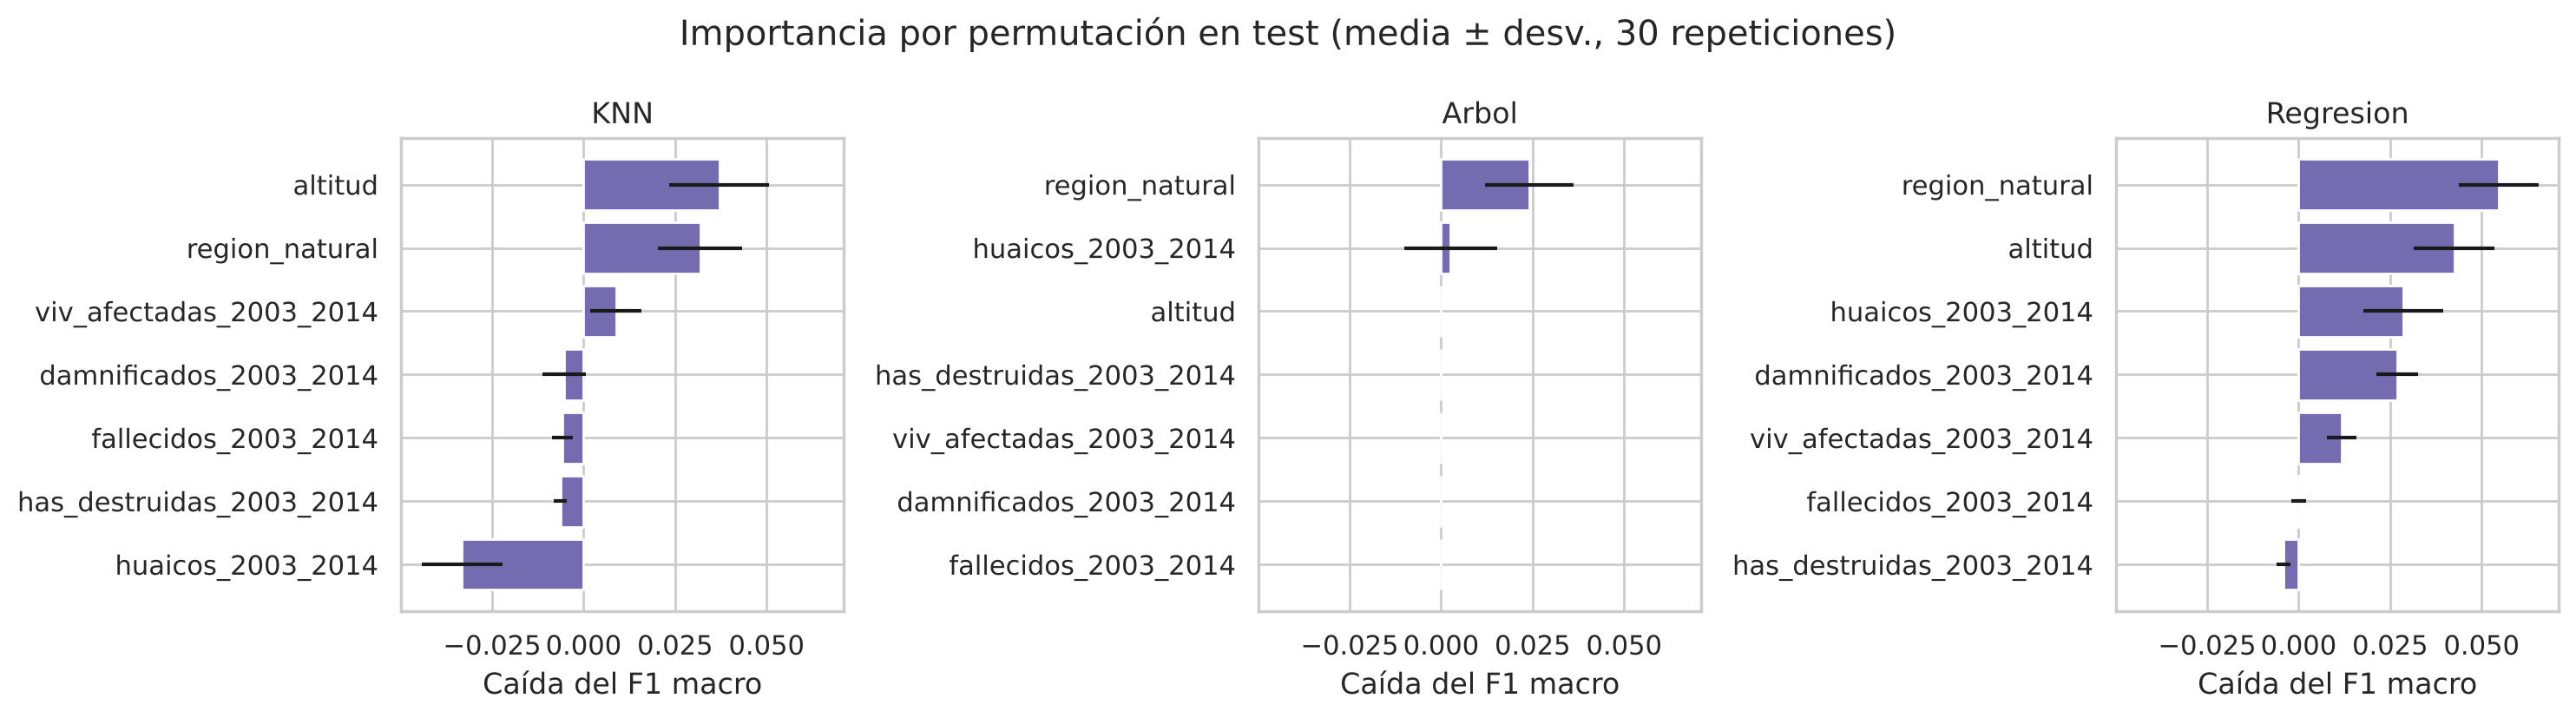

,KNN,Arbol,Regresion
huaicos_2003_2014,-0.0332,0.0025,0.0286
fallecidos_2003_2014,-0.0058,0.0000,0.0001
damnificados_2003_2014,-0.0054,0.0000,0.0270
viv_afectadas_2003_2014,0.0088,0.0000,0.0118
has_destruidas_2003_2014,-0.0063,0.0000,-0.0041
altitud,0.0371,0.0000,0.0425
region_natural,0.0319,0.0240,0.0547


In [ ]:
IMP = {}
for n in MODELOS:
    r = permutation_importance(AJ[n], Xte, yte, scoring="f1_macro", n_repeats=30, random_state=SEED, n_jobs=-1)
    IMP[n] = pd.DataFrame({"media": r.importances_mean, "desv": r.importances_std}, index=Xte.columns)

fig, ejes = plt.subplots(1, 3, figsize=(15, 4.2), sharex=True)
for ax, n in zip(ejes, MODELOS):
    d = IMP[n].sort_values("media")
    ax.barh(d.index, d["media"], xerr=d["desv"], color="#756bb1"); ax.set_title(n)
    ax.set_xlabel("Caída del F1 macro")
fig.suptitle("Importancia por permutación en test (media ± desv., 30 repeticiones)")
plt.tight_layout(); plt.show()
pd.concat({n: IMP[n]["media"] for n in MODELOS}, axis=1).round(4)

In [ ]:
rl = AJ["Regresion"].named_steps["modelo"]
cl = list(rl.classes_)
coef = pd.Series(rl.coef_[cl.index("Alto")] - rl.coef_[cl.index("Bajo")], index=nombres_features(AJ["Regresion"]))
num_coef = coef[NUM_LOG + ["altitud"]]
reg_coef = coef[[c for c in coef.index if c.startswith("region=")]]
reg_vs_costa = (reg_coef - reg_coef["region=COSTA"]).drop("region=COSTA")
reg_vs_costa.index = [c.replace("region=", "") + " vs COSTA" for c in reg_vs_costa.index]
COEF = pd.concat([num_coef, reg_vs_costa]).to_frame("Log-odds Alto vs Bajo")
COEF["Odds ratio exp(b)"] = np.exp(COEF["Log-odds Alto vs Bajo"])
COEF.reindex(COEF["Log-odds Alto vs Bajo"].abs().sort_values(ascending=False).index)

,Log-odds Alto vs Bajo,Odds ratio exp(b)
SELVA BAJA vs COSTA,-1.4012,0.2463
SELVA ALTA vs COSTA,-0.8554,0.4251
SIERRA vs COSTA,-0.4468,0.6397
altitud,-0.3954,0.6734
damnificados_2003_2014,0.3419,1.4077
viv_afectadas_2003_2014,0.1943,1.2144
huaicos_2003_2014,-0.1875,0.8290
fallecidos_2003_2014,-0.1392,0.8700
has_destruidas_2003_2014,-0.1259,0.8817


**Lectura de las variables:**
- **Importancia por permutación:** en KNN y la Regresión, la altitud y la región son las variables cuya permutación más reduce el F1 macro. El Árbol de profundidad 3 usa sobre todo la región (0,024); la altitud no aporta en él (0,000) porque, al estar correlacionada con la región, el árbol usa solo una de las dos.
- **Coeficientes de la Regresión (Alto frente a Bajo):** frente a un distrito costeño, las odds de ser Alto en vez de Bajo son menores en Selva Baja (×0,25), Selva Alta (×0,43) y Sierra (×0,64); cada desviación estándar más de altitud las reduce (×0,67) y cada desviación estándar más de damnificados históricos las aumenta (×1,41). Los distritos **costeños, de menor altitud y con más damnificados en el pasado** se asocian con daño Alto. Por la regularización fuerte (C = 0,01), se leen el signo y el orden, no la magnitud.

## C.9 Utilidad para priorizar distritos
Priorizar es **ordenar** los distritos de mayor a menor riesgo, no solo asignarles una clase. Se usa la probabilidad de Alto que da cada modelo en el test:
- **AUC-PR de Alto** (área bajo la curva precisión-recall): resume qué tan bien quedan los distritos Alto en los primeros lugares. Un orden al azar obtiene, en promedio, la proporción de Alto del test.
- **Distritos Alto entre los k primeros:** si se atendieran primero los k distritos con mayor probabilidad de Alto, ¿cuántos serían realmente Alto? Se compara con lo que se esperaría eligiendo al azar.

In [ ]:
es_alto = (yte == "Alto").values
tasa = es_alto.mean()
print(f"Distritos Alto en test: {es_alto.sum()} de {len(es_alto)} ({tasa:.1%})")
filas = []
for n in MODELOS:
    p_alto = AJ[n].predict_proba(Xte)[:, list(AJ[n].classes_).index("Alto")]
    orden = np.argsort(-p_alto, kind="stable")
    fila = {"Modelo": n, "AUC-PR Alto": average_precision_score(es_alto, p_alto)}
    for k in [25, 50, 100]:
        fila[f"Alto en los {k} primeros"] = int(es_alto[orden[:k]].sum())
    filas.append(fila)
filas.append({"Modelo": "Al azar (esperado)", "AUC-PR Alto": tasa,
              **{f"Alto en los {k} primeros": round(k * tasa, 1) for k in [25, 50, 100]}})
PRIORIZA = pd.DataFrame(filas).set_index("Modelo")
PRIORIZA

Distritos Alto en test: 31 de 551 (5.6%)


,AUC-PR Alto,Alto en los 25 primeros,Alto en los 50 primeros,Alto en los 100 primeros
Modelo,,,,
KNN,0.0634,1.0000,4.0000,7.0000
Arbol,0.0717,2.0000,4.0000,10.0000
Regresion,0.0672,0.0000,1.0000,10.0000
Al azar (esperado),0.0563,1.4000,2.8000,5.6000


**Lectura de la priorización:**
- El AUC-PR de Alto está entre 0,063 y 0,072, apenas por encima del 0,056 de un orden al azar: **ordenar por la probabilidad de Alto prioriza solo un poco mejor que el azar**.
- Entre los 100 distritos con mayor probabilidad de Alto, el Árbol y la Regresión encuentran 10 distritos Alto, frente a 5,6 esperados al azar (casi el doble). Pero entre los 25 primeros, la Regresión no encuentra ninguno y el Árbol, 2 (azar: 1,4).
- **Conclusión:** con estas variables, los modelos identifican un **grupo amplio de distritos con más riesgo**, pero no sirven para un ranking fino de los más críticos.

## C.10 Incertidumbre en el test (bootstrap)
Con 31 distritos Alto en el test, cada acierto mueve el recall de Alto en 3,2 puntos. Para ver cuánto se solapan los modelos se remuestrea el test 1 000 veces (bootstrap) y se calcula el intervalo de confianza al 95 % de cada métrica y de la diferencia entre la Regresión y los otros modelos (mismas muestras para todos, comparación pareada).

In [ ]:
rng = np.random.default_rng(SEED)
yv = yte.values
B = 1000
boot = {n: {"F1 macro": [], "Recall Alto": []} for n in ["Base"] + MODELOS}
for _ in range(B):
    idx = rng.integers(0, len(yv), len(yv))
    for n in ["Base"] + MODELOS:
        boot[n]["F1 macro"].append(f1_score(yv[idx], PRED[n][idx], average="macro"))
        boot[n]["Recall Alto"].append(recall_alto(yv[idx], PRED[n][idx]))
ic = lambda v: f"[{np.percentile(v, 2.5):.3f} ; {np.percentile(v, 97.5):.3f}]"
filas = [{"Modelo": n, **{f"IC 95 % {m}": ic(boot[n][m]) for m in ["F1 macro", "Recall Alto"]}} for n in ["Base"] + MODELOS]
for b in ["KNN", "Arbol", "Base"]:
    filas.append({"Modelo": f"Regresion − {b}",
                  **{f"IC 95 % {m}": ic(np.array(boot["Regresion"][m]) - np.array(boot[b][m])) for m in ["F1 macro", "Recall Alto"]}})
pd.DataFrame(filas).set_index("Modelo")

,IC 95 % F1 macro,IC 95 % Recall Alto
Modelo,,
Base,[0.309 ; 0.318],[0.000 ; 0.000]
KNN,[0.262 ; 0.335],[0.111 ; 0.419]
Arbol,[0.311 ; 0.391],[0.185 ; 0.546]
Regresion,[0.313 ; 0.399],[0.185 ; 0.546]
Regresion − KNN,[0.016 ; 0.103],[-0.086 ; 0.300]
Regresion − Arbol,[-0.029 ; 0.038],[0.000 ; 0.000]
Regresion − Base,[-0.004 ; 0.087],[0.185 ; 0.546]


**Lectura del bootstrap:**
- Los intervalos del F1 macro de la Regresión [0,313; 0,399] y del Árbol [0,311; 0,391] se solapan casi por completo, y la diferencia Regresión − Árbol incluye el 0 [−0,029; 0,038]: **en test están empatados**. El Árbol y la Regresión detectan exactamente los mismos distritos Alto (la diferencia de recall es 0 en todas las remuestras).
- La Regresión supera a KNN en F1 macro en test (diferencia [0,016; 0,103], no incluye el 0).
- Frente a la base, la diferencia en F1 macro de la Regresión incluye el 0 [−0,004; 0,087]: **en test, la ventaja sobre la base en F1 macro no es concluyente**, aunque el recall de Alto sí es claramente mayor [0,185; 0,546].

## C.11 Verificación de la grilla
Todos los hiperparámetros elegidos deben quedar dentro del rango probado; si alguno quedara en el borde, el óptimo podría estar fuera de la grilla.

In [ ]:
for titulo, P in [("Experimento 1 (etiqueta de daño)", PAR), ("Experimento 4 (etiqueta mixta)", PAR_ALT)]:
    print(f"Hiperparámetros elegidos — {titulo}:")
    for n in MODELOS:
        for k, v in P[n].items():
            valores = GRILLAS[n]["modelo__" + k]
            borde = (v == valores[0] or v == valores[-1]) and not isinstance(v, str)
            print(f"  {n} · {k} = {v}  →  {'EN EL BORDE' if borde else 'dentro del rango'}  (grilla: {valores})")

Hiperparámetros elegidos — Experimento 1 (etiqueta de daño):
  KNN · n_neighbors = 9  →  dentro del rango  (grilla: [3, 5, 7, 9, 11, 15, 21, 31])
  KNN · weights = distance  →  dentro del rango  (grilla: ['uniform', 'distance'])
  Arbol · max_depth = 3  →  dentro del rango  (grilla: [2, 3, 5, 7, 10, 15, None])
  Arbol · min_samples_leaf = 300  →  dentro del rango  (grilla: [1, 5, 10, 20, 50, 100, 150, 200, 300, 400, 600])
  Regresion · C = 0.01  →  dentro del rango  (grilla: [0.001, 0.01, 0.1, 1, 10, 100])
Hiperparámetros elegidos — Experimento 4 (etiqueta mixta):
  KNN · n_neighbors = 15  →  dentro del rango  (grilla: [3, 5, 7, 9, 11, 15, 21, 31])
  KNN · weights = distance  →  dentro del rango  (grilla: ['uniform', 'distance'])
  Arbol · max_depth = 3  →  dentro del rango  (grilla: [2, 3, 5, 7, 10, 15, None])
  Arbol · min_samples_leaf = 300  →  dentro del rango  (grilla: [1, 5, 10, 20, 50, 100, 150, 200, 300, 400, 600])
  Regresion · C = 10  →  dentro del rango  (grilla: [0.001, 0.0